# Entregable 1

## Predicción del Brent Equivalent Production Cost en Activos Upstream de Oil & Gas mediante Machine Learning

**Estudiante:** Leonella Torreglosa Portillo

**Asignatura:** Machine Learning

**Programa:** Maestría en Ingeniería Industrial

**Fecha:** Octubre 2026

In [1]:
import numpy as np
import random

SEED = 42

np.random.seed(SEED)
random.seed(SEED)

Todas las semillas aleatorias fueron fijadas en 42 para garantizar la reproducibilidad de los resultados.

# 1. Base de Datos

## 1.1 Definición del problema de investigación

Los costos de producción constituyen una de las variables más relevantes para la evaluación económica de activos upstream de petróleo. Estos costos pueden variar significativamente entre activos debido a diferencias geológicas, geográficas, operativas y tecnológicas.

La disponibilidad de información histórica de activos petroleros alrededor del mundo permite analizar los factores asociados a dichas variaciones e implementar modelos predictivos que apoyen la comprensión del comportamiento de los costos de producción.

En este proyecto se propone desarrollar un modelo de Machine Learning capaz de estimar el indicador Brent Equivalent Production Cost (USD/Bbl) utilizando variables operativas, económicas y geográficas provenientes de activos upstream de petróleo distribuidos globalmente.

## 1.2 Justificación de la selección del dataset

La base de datos seleccionada contiene información histórica de activos upstream de petróleo localizados en diferentes regiones del mundo, incluyendo variables relacionadas con producción, costos de producción, costos de desarrollo y características operativas de los activos.

El dataset resulta adecuado para abordar el problema de investigación debido a que:

- Incluye observaciones de múltiples países y regiones.
- Contiene variables económicas directamente relacionadas con los costos de producción.
- Permite analizar diferencias entre tipos de reservas y métodos de explotación.
- Presenta cobertura temporal entre 2015 y 2023.
- Contiene variables continuas y categóricas aptas para modelos de regresión supervisada.

Adicionalmente, la información proviene de una fuente especializada ampliamente utilizada dentro de la industria energética.

## 1.3 Fuente de los datos y licencia

La información utilizada en este proyecto proviene de S&P Global Commodity Insights, específicamente del módulo Supply Cost and Ownership.

Fuente:

https://core.spglobal.com/#platts/workspace?menuserviceline=Crude%20Oil&workspace=Supply%20Cost%20and%20Ownership&view=preview

La base contiene información histórica de costos y producción de activos upstream de petróleo para diferentes regiones del mundo.

El acceso a los datos se realiza mediante una licencia corporativa provista por la organización empleadora del investigador.

Con el fin de responder adecuadamente a la pregunta de investigación, se aplicaron filtros y transformaciones sobre la extracción original para conservar únicamente los registros relacionados con activos upstream relevantes para el análisis de costos de producción.

## 1.4 Diccionario de variables

| Variable | Tipo | Unidad | Descripción |
|-----------|-----------|-----------|-----------|
| RegionName | Categórica | N/A | Región geográfica del activo |
| CountryName | Categórica | N/A | País donde se ubica el activo |
| ReserveTypeName | Categórica | N/A | Tipo de reserva |
| SupplyTypeName | Categórica | N/A | Tipo de suministro |
| SupplySubTypeName | Categórica | N/A | Subtipo de explotación |
| ReserveLocationName | Categórica | N/A | Ubicación general de la reserva |
| ProductionElementName | Categórica | N/A | Región o cuenca productiva |
| CostProductionElementName | Categórica | N/A | Nombre del activo o campo |
| MemberOpec | Categórica | N/A | Pertenencia a OPEP |
| Year | Numérica discreta | Año | Año de observación |
| Production | Numérica continua | MBD | Producción diaria promedio |
| BrentDifferential | Numérica continua | USD/Bbl | Diferencial respecto al Brent |
| WellheadProductionCost | Numérica continua | USD/Bbl | Costo de producción en cabeza de pozo |
| WellheadDevelopmentCost | Numérica continua | USD/Bbl | Costo de desarrollo en cabeza de pozo |
| BrentEquivalentDevelopmentCost | Numérica continua | USD/Bbl | Costo equivalente de desarrollo |
| BrentEquivalentProductionCost | Numérica continua | USD/Bbl | Costo equivalente de producción (variable objetivo) |

## 1.5 Estructura de los datos

### Unidad de observación

La unidad de observación corresponde a un activo upstream de petróleo observado durante un año específico.

Ejemplos:

- Rubiales (Colombia) – 2019.
- Dalia (Angola) – 2020.
- Johan Sverdrup (Noruega) – 2022.

### Nivel de agregación

Activo-año.

### Tipo de datos

Panel longitudinal con componente geográfico.

### Cobertura temporal

2014–2023.

### Cobertura geográfica

La base incluye activos ubicados en 99 países distribuidos en 14 regiones geográficas del mundo.

## 1.6 Tamaño de la muestra

La base de datos contiene 4.595 observaciones correspondientes a activos upstream de petróleo observados entre 2014 y 2023.

### Dimensionalidad

- Número de observaciones (n): 4.595
- Número de variables (p): 17
- Relación n/p: 270,29

La relación n/p indica una proporción adecuada entre observaciones y variables para el desarrollo de modelos supervisados.

### Variable objetivo

La variable objetivo seleccionada corresponde a:

**BrentEquivalentProductionCost (USD/Bbl)**

La variable es continua, por lo que el problema se clasifica como una tarea de regresión supervisada.

### Rango de la variable objetivo

El rango será calculado mediante estadística descriptiva sobre la variable objetivo y reportado en la sección de análisis exploratorio.

### Entidades independientes

La entidad principal corresponde al activo upstream identificado mediante la variable CostProductionElementName.

El dataset contiene 703 activos diferentes distribuidos en 99 países y 14 regiones.

Dado que un mismo activo puede aparecer en varios años consecutivos, el tamaño efectivo de la muestra es menor que el número total de filas y debe tenerse en cuenta durante la validación del modelo.


In [2]:
import pandas as pd

df = pd.read_csv(
    "C:\\Users\\Leonella Torreglosa\\OneDrive\\Escritorio\\MachineLearningUN\\MLProject\\DatasetOilCostProjectWorldwide.csv",
    sep=";"
)

df.head()

,Commodity,RegionName,CountryName,ReserveTypeName,SupplyTypeName,SupplySubTypeName,ReserveLocationName,ProductionElementName,CostProductionElementName,MemberOpec,Year,BrentDifferential,BrentEquivalentProductionCost,WellheadDevelopmentCost,BrentEquivalentDevelopmentCost,WellheadProductionCost,Production
0,Crude oil,Eastern Asia,Taiwan,Conventional,Crude,Non-Shale,Onshore,Far East - Except China,Taiwan,NON - OPEC,2014,NaN,NaN,NaN,NaN,NaN,NaN
1,Crude oil,Eastern Asia,Taiwan,Conventional,Crude,Non-Shale,Onshore,Far East - Except China,Taiwan,NON - OPEC,2015,-1.68,8.00,40.66,38.98,9.68,0.12
2,Crude oil,Eastern Asia,Taiwan,Conventional,Crude,Non-Shale,Onshore,Far East - Except China,Taiwan,NON - OPEC,2016,-1.68,7.52,38.22,36.54,9.20,0.15
3,Crude oil,Eastern Asia,Taiwan,Conventional,Crude,Non-Shale,Onshore,Far East - Except China,Taiwan,NON - OPEC,2017,-1.51,7.22,35.93,34.42,8.74,0.15
4,Crude oil,Eastern Asia,Taiwan,Conventional,Crude,Non-Shale,Onshore,Far East - Except China,Taiwan,NON - OPEC,2018,-1.51,6.88,34.49,32.98,8.39,0.14


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4595 entries, 0 to 4594
Data columns (total 17 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Commodity                       4595 non-null   object 
 1   RegionName                      4595 non-null   object 
 2   CountryName                     4595 non-null   object 
 3   ReserveTypeName                 4595 non-null   object 
 4   SupplyTypeName                  4595 non-null   object 
 5   SupplySubTypeName               4595 non-null   object 
 6   ReserveLocationName             4595 non-null   object 
 7   ProductionElementName           4595 non-null   object 
 8   CostProductionElementName       4595 non-null   object 
 9   MemberOpec                      4595 non-null   object 
 10  Year                            4595 non-null   int64  
 11  BrentDifferential               3817 non-null   float64
 12  BrentEquivalentProductionCost   38

In [4]:
df.shape
df.nunique()

Commodity                            1
RegionName                          14
CountryName                         99
ReserveTypeName                      2
SupplyTypeName                       1
SupplySubTypeName                    5
ReserveLocationName                  3
ProductionElementName               69
CostProductionElementName          703
MemberOpec                           2
Year                                10
BrentDifferential                  527
BrentEquivalentProductionCost     1116
WellheadDevelopmentCost           1299
BrentEquivalentDevelopmentCost    1440
WellheadProductionCost             806
Production                        2537
dtype: int64

> Nota: la extracción original fue sometida a un proceso de filtrado y consolidación para conservar únicamente observaciones relacionadas con activos upstream relevantes para la pregunta de investigación. Como resultado, la muestra final utilizada en el estudio contiene 4.595 observaciones.

In [5]:
df.isnull().sum()

Commodity                            0
RegionName                           0
CountryName                          0
ReserveTypeName                      0
SupplyTypeName                       0
SupplySubTypeName                    0
ReserveLocationName                  0
ProductionElementName                0
CostProductionElementName            0
MemberOpec                           0
Year                                 0
BrentDifferential                  778
BrentEquivalentProductionCost      761
WellheadDevelopmentCost           1034
BrentEquivalentDevelopmentCost     786
WellheadProductionCost            1572
Production                        1572
dtype: int64

In [6]:
(df.isnull().sum()/len(df)*100).round(2)

Commodity                          0.00
RegionName                         0.00
CountryName                        0.00
ReserveTypeName                    0.00
SupplyTypeName                     0.00
SupplySubTypeName                  0.00
ReserveLocationName                0.00
ProductionElementName              0.00
CostProductionElementName          0.00
MemberOpec                         0.00
Year                               0.00
BrentDifferential                 16.93
BrentEquivalentProductionCost     16.56
WellheadDevelopmentCost           22.50
BrentEquivalentDevelopmentCost    17.11
WellheadProductionCost            34.21
Production                        34.21
dtype: float64

## 1.7 Calidad de los datos

### Valores faltantes

Se realizó una evaluación inicial de valores faltantes utilizando una matriz de nulidad.

#### Resumen de valores faltantes

| Variable | Valores faltantes | % faltantes |
|-----------|-----------:|-----------:|
| BrentDifferential | 778 | 16.93% |
| BrentEquivalentProductionCost | 761 | 16.56% |
| WellheadDevelopmentCost | 1.034 | 22.50% |
| BrentEquivalentDevelopmentCost | 786 | 17.11% |
| WellheadProductionCost | 1.572 | 34.21% |
| Production | 1.572 | 34.21% |

Las variables categóricas y temporales no presentan valores faltantes.

La mayor proporción de ausencia corresponde a las variables Production y WellheadProductionCost, con aproximadamente el 34% de registros faltantes.

#### Evaluación preliminar del mecanismo de ausencia

A partir de la matriz de nulidad se observa que los valores faltantes se concentran en determinadas variables económicas y operativas, mientras que las variables descriptivas del activo permanecen completas.

Esta situación sugiere que la ausencia de datos no corresponde a un mecanismo completamente aleatorio (MCAR). De manera preliminar se plantea que los datos podrían responder a mecanismos MAR (Missing At Random) o MNAR (Missing Not At Random), asociados a características específicas de determinados activos, regiones o tipos de explotación.

La validación definitiva del mecanismo de ausencia se realizará mediante comparación estadística entre registros completos e incompletos durante el análisis exploratorio.

<Figure size 1200x600 with 0 Axes>

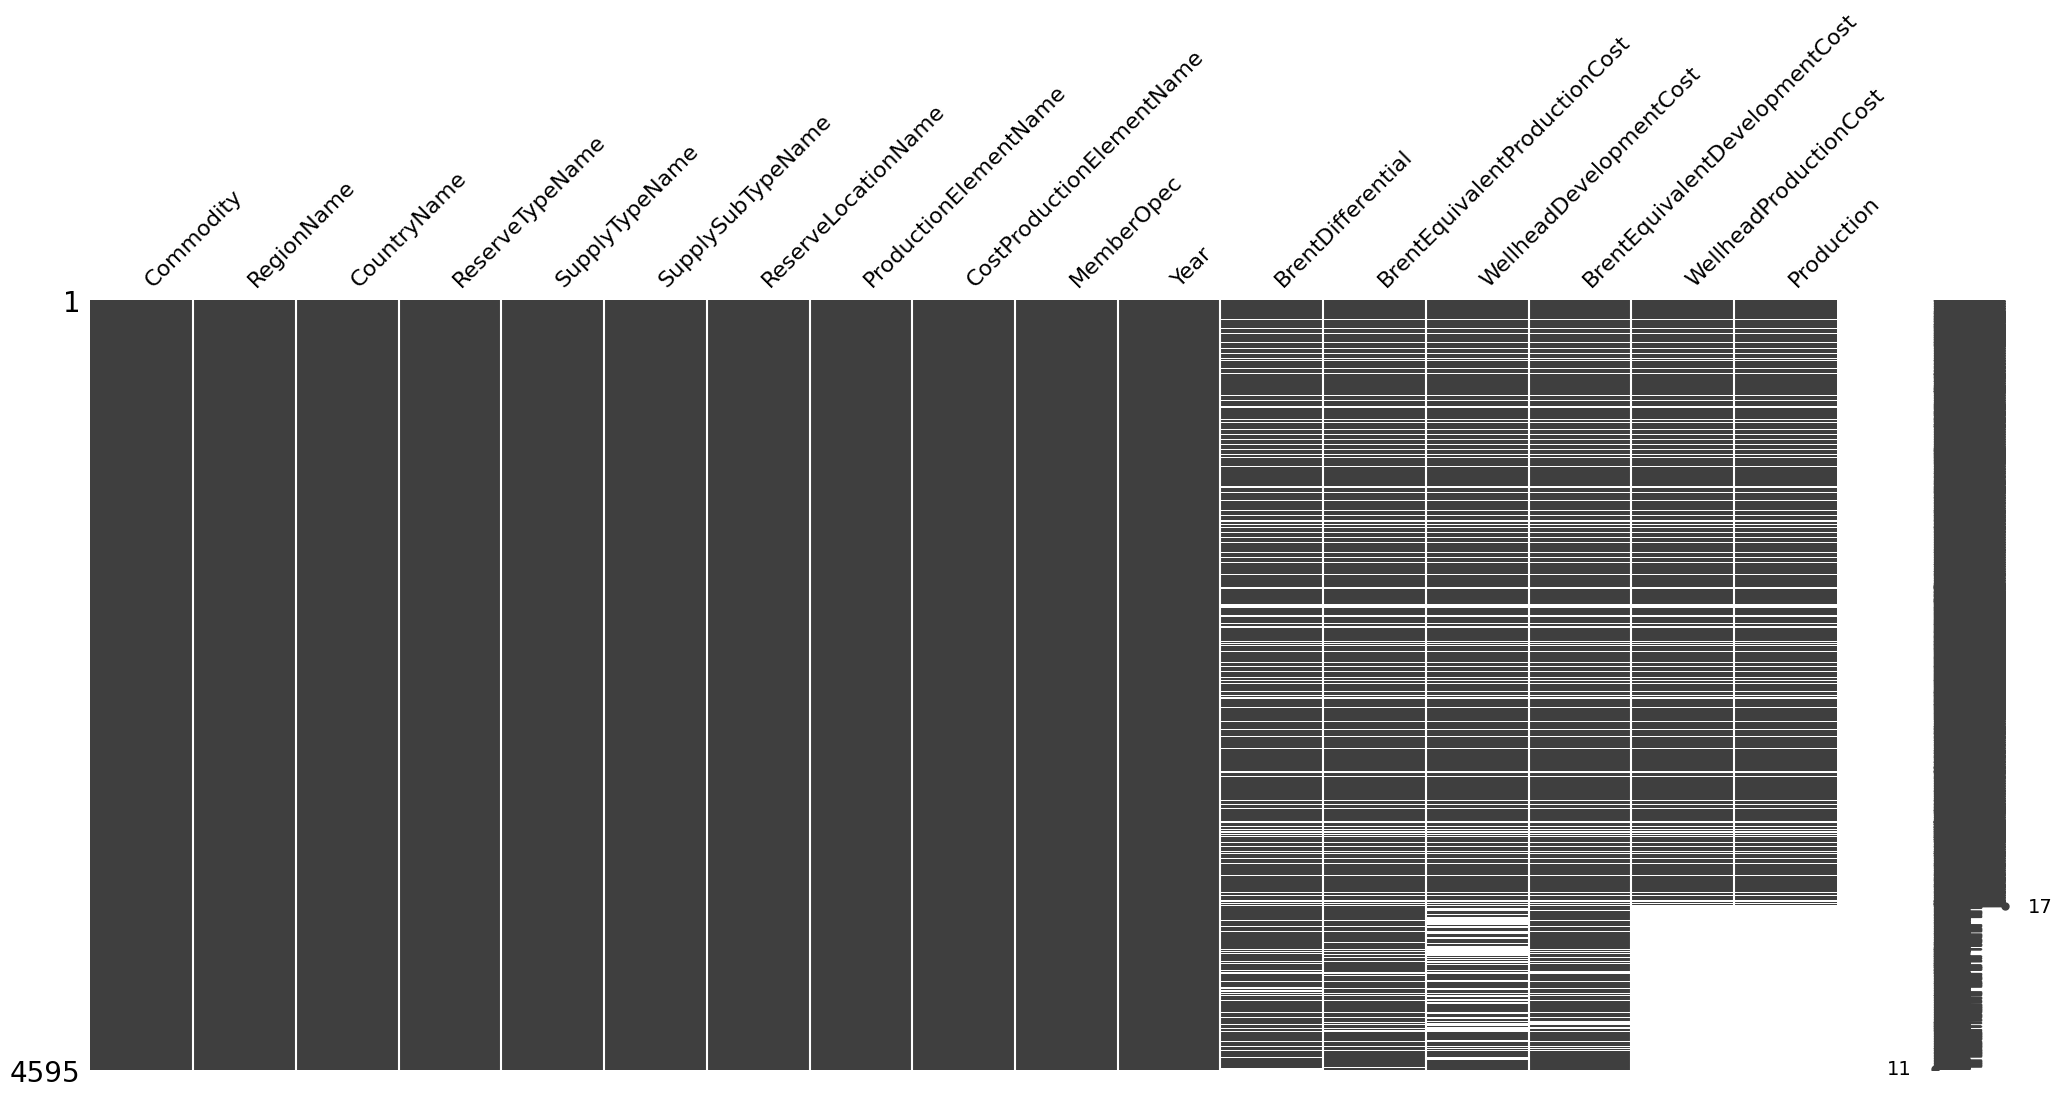

In [7]:
import missingno as msno
import matplotlib.pyplot as plt

plt.figure(figsize=(12,6))
msno.matrix(df)
plt.show()


In [8]:
df.duplicated().sum()

0

In [9]:
df[df.duplicated()]

,Commodity,RegionName,CountryName,ReserveTypeName,SupplyTypeName,SupplySubTypeName,ReserveLocationName,ProductionElementName,CostProductionElementName,MemberOpec,Year,BrentDifferential,BrentEquivalentProductionCost,WellheadDevelopmentCost,BrentEquivalentDevelopmentCost,WellheadProductionCost,Production


### Duplicados exactos

No se identificaron registros duplicados exactos dentro del dataset.

Cada observación corresponde a una combinación única de activo y año.

### Outliers

Se realizó una evaluación exploratoria de valores atípicos mediante diagramas de caja (boxplots) para las variables numéricas del dataset.

El objetivo es identificar observaciones extremas que puedan influir significativamente en las estimaciones de los modelos predictivos.

In [10]:
variables_numericas = [
    "BrentDifferential",
    "BrentEquivalentProductionCost",
    "WellheadDevelopmentCost",
    "BrentEquivalentDevelopmentCost",
    "WellheadProductionCost",
    "Production"
]

df[variables_numericas].describe()

,BrentDifferential,BrentEquivalentProductionCost,WellheadDevelopmentCost,BrentEquivalentDevelopmentCost,WellheadProductionCost,Production
count,3817.000000,3834.000000,3561.000000,3809.000000,3023.000000,3023.000000
mean,3.508756,14.276435,42.851758,46.332221,10.938806,188.223592
std,3.359596,5.538397,11.164243,11.441058,4.316737,523.251603
min,-3.600000,3.030000,12.730000,18.630000,-0.170000,0.000000
25%,1.260000,10.680000,36.150000,39.600000,8.300000,10.250000
50%,3.000000,12.945000,43.460000,46.890000,10.580000,37.950000
75%,5.010000,17.250000,50.560000,54.240000,13.545000,131.240000
max,25.320000,54.470000,79.000000,85.890000,38.980000,5901.040000


c:\LeonellaTP\Miniconda3\envs\ml_venv\lib\site-packages\seaborn\_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
c:\LeonellaTP\Miniconda3\envs\ml_venv\lib\site-packages\seaborn\_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
c:\LeonellaTP\Miniconda3\envs\ml_venv\lib\site-packages\seaborn\_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
c:\LeonellaTP\Miniconda3\envs\ml_venv\lib\site-packages\seaborn\_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype

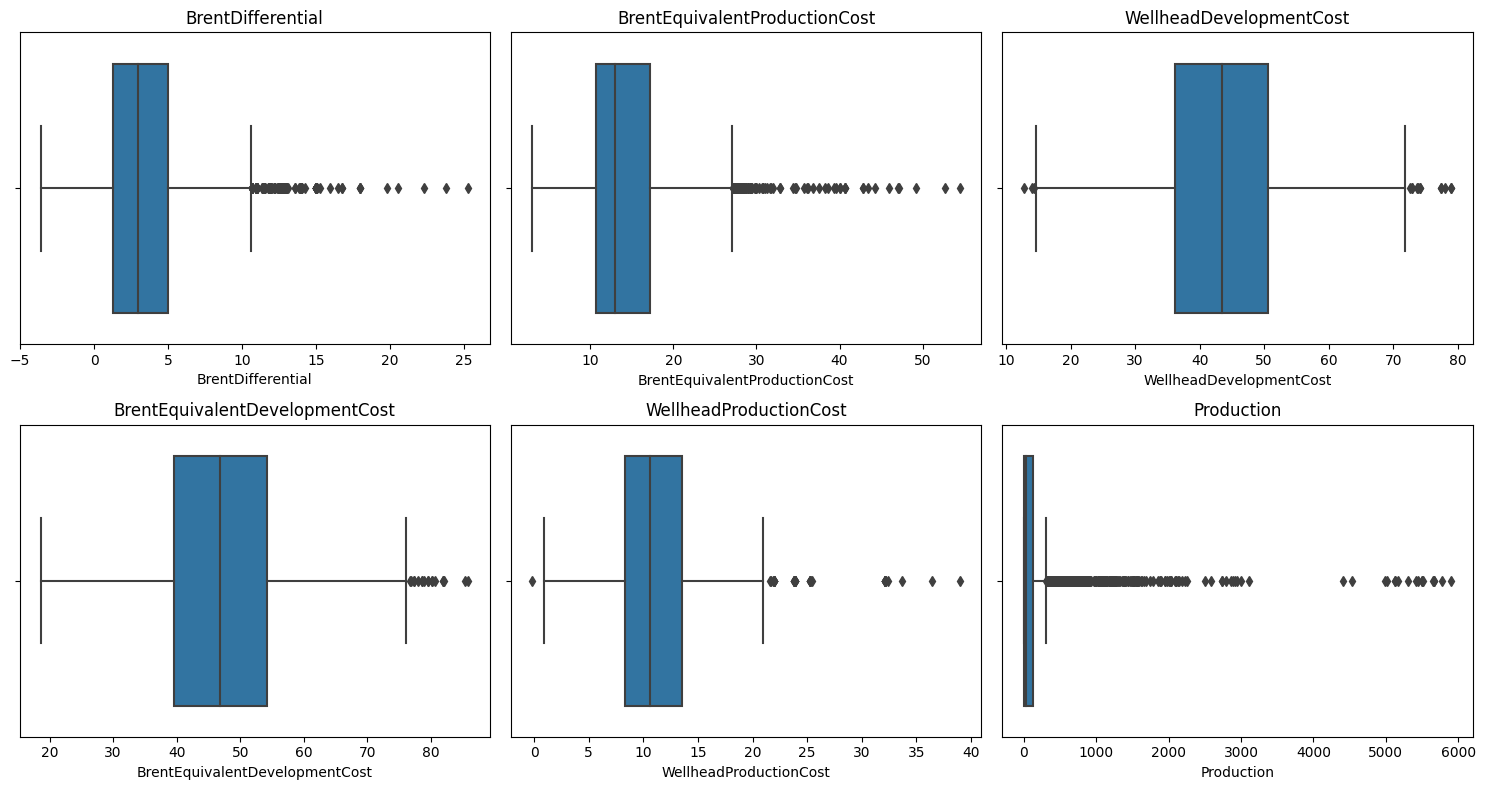

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(2,3, figsize=(15,8))

for ax, col in zip(axes.flatten(), variables_numericas):
    sns.boxplot(x=df[col], ax=ax)
    ax.set_title(col)

plt.tight_layout()
plt.show()

#### Interpretación

Los diagramas de caja muestran la presencia de valores atípicos en todas las variables numéricas analizadas.

Las variables BrentDifferential, BrentEquivalentProductionCost, WellheadDevelopmentCost, BrentEquivalentDevelopmentCost y WellheadProductionCost presentan observaciones extremas superiores, aunque la mayor parte de los registros se concentra dentro de rangos relativamente estables.

La variable Production presenta la mayor dispersión y la mayor cantidad de valores atípicos. Este comportamiento es consistente con la naturaleza del sector Oil & Gas, donde existen diferencias significativas de escala entre activos pequeños y grandes productores.

Desde una perspectiva de negocio, estos valores no representan necesariamente errores de captura, sino activos con capacidades productivas sustancialmente diferentes. Por esta razón, los outliers identificados serán analizados individualmente antes de considerar cualquier transformación o tratamiento.

Dado el contexto industrial de la base de datos, la eliminación automática de observaciones extremas podría generar pérdida de información relevante sobre activos de alta producción.

### Valores imposibles o inconsistentes

Se evaluaron los rangos mínimos y máximos de las variables numéricas para identificar posibles errores de captura, inconsistencias de unidades o valores físicamente imposibles.

In [12]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Year,4595.0,2018.280740,3.000067,2014.00,2015.00,2018.000,2021.000,2023.00
BrentDifferential,3817.0,3.508756,3.359596,-3.60,1.26,3.000,5.010,25.32
BrentEquivalentProductionCost,3834.0,14.276435,5.538397,3.03,10.68,12.945,17.250,54.47
WellheadDevelopmentCost,3561.0,42.851758,11.164243,12.73,36.15,43.460,50.560,79.00
BrentEquivalentDevelopmentCost,3809.0,46.332221,11.441058,18.63,39.60,46.890,54.240,85.89
WellheadProductionCost,3023.0,10.938806,4.316737,-0.17,8.30,10.580,13.545,38.98
Production,3023.0,188.223592,523.251603,0.00,10.25,37.950,131.240,5901.04


In [13]:
for col in [
    "BrentDifferential",
    "BrentEquivalentProductionCost",
    "WellheadDevelopmentCost",
    "BrentEquivalentDevelopmentCost",
    "WellheadProductionCost",
    "Production"
]:
    print(col)
    print("Min:", df[col].min())
    print("Max:", df[col].max())
    print("-"*30)

BrentDifferential
Min: -3.6
Max: 25.32
------------------------------
BrentEquivalentProductionCost
Min: 3.03
Max: 54.47
------------------------------
WellheadDevelopmentCost
Min: 12.73
Max: 79.0
------------------------------
BrentEquivalentDevelopmentCost
Min: 18.63
Max: 85.89
------------------------------
WellheadProductionCost
Min: -0.17
Max: 38.98
------------------------------
Production
Min: 0.0
Max: 5901.04
------------------------------


#### Interpretación

La revisión de rangos permitió identificar las siguientes características:

- BrentDifferential presenta valores entre -3.60 y 25.32 USD/Bbl.
- BrentEquivalentProductionCost presenta valores entre 3.03 y 54.47 USD/Bbl.
- WellheadDevelopmentCost presenta valores entre 12.73 y 79.00 USD/Bbl.
- BrentEquivalentDevelopmentCost presenta valores entre 18.63 y 85.89 USD/Bbl.
- WellheadProductionCost presenta valores entre -0.17 y 38.98 USD/Bbl.
- Production presenta valores entre 0 y 5901.04 MBD.

Los valores negativos observados en BrentDifferential son consistentes con descuentos comerciales respecto al precio de referencia Brent y no representan errores de captura.

El valor mínimo de WellheadProductionCost (-0.17 USD/Bbl) será revisado posteriormente debido a que un costo de producción negativo puede indicar un ajuste contable, una metodología específica de cálculo o una posible anomalía en los datos.

Los valores elevados de Production son coherentes con la existencia de activos de gran escala localizados principalmente en países productores de gran relevancia como Arabia Saudí, Estados Unidos, Irak o Rusia.

No se identificaron inconsistencias evidentes en unidades de medida debido a que todos los costos se encuentran expresados en USD/Bbl y la producción se registra en MBD.

### Sesgos de muestreo y representatividad

Se analizó la distribución de observaciones por región geográfica, tipo de reserva y pertenencia a la OPEP con el fin de evaluar la representatividad de la muestra respecto a la población objetivo.

In [14]:
df["RegionName"].value_counts()

RegionName
North America                      1143
Africa                              747
Latin America and the Caribbean     563
Middle East                         500
Northern Europe                     468
Eastern Europe                      290
South-eastern Asia                  265
Eastern Asia                        160
Oceania                             104
Southern Europe                      94
Central Asia                         79
Western Europe                       75
Western Asia                         56
Southern Asia                        51
Name: count, dtype: int64

In [15]:
df["ReserveTypeName"].value_counts()

ReserveTypeName
Conventional      4427
Unconventional     168
Name: count, dtype: int64

In [16]:
df["MemberOpec"].value_counts()

MemberOpec
NON - OPEC    3664
OPEC           931
Name: count, dtype: int64

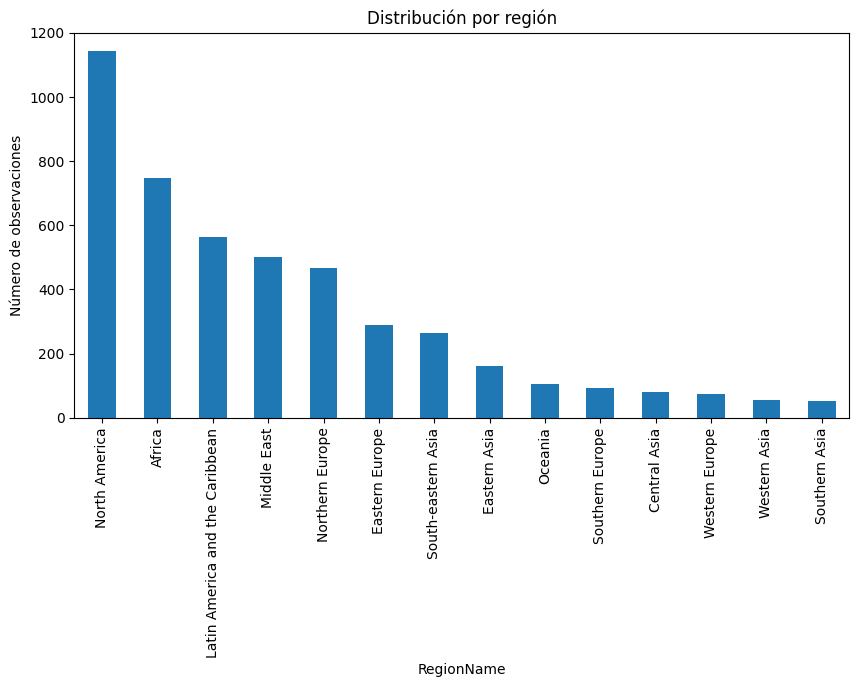

In [17]:
import matplotlib.pyplot as plt

df["RegionName"].value_counts().plot(
    kind="bar",
    figsize=(10,5)
)

plt.title("Distribución por región")
plt.ylabel("Número de observaciones")
plt.show()

#### Interpretación

La distribución geográfica de la muestra no es uniforme.

Las regiones con mayor representación son:

- North America: 1.143 observaciones.
- Africa: 747 observaciones.
- Latin America and the Caribbean: 563 observaciones.
- Middle East: 500 observaciones.
- Northern Europe: 468 observaciones.

Por el contrario, regiones como Southern Asia, Western Asia y Western Europe presentan una representación considerablemente menor.

En cuanto al tipo de reserva, la muestra se encuentra dominada por activos convencionales:

- Conventional: 4.427 observaciones (96.34%).
- Unconventional: 168 observaciones (3.66%).

Respecto a la pertenencia a la OPEP:

- NON-OPEC: 3.664 observaciones (79.74%).
- OPEC: 931 observaciones (20.26%).

Estos resultados indican que la muestra representa principalmente activos convencionales y activos localizados en Norteamérica, África y América Latina.

Por lo tanto, los resultados del modelo podrían generalizar mejor hacia este tipo de activos que hacia activos no convencionales o regiones con menor representación.

## 1.8 Consideraciones éticas

La base de datos utilizada no contiene información personal identificable ni datos sensibles asociados a individuos.

Las observaciones corresponden exclusivamente a activos industriales de la industria Oil & Gas y a variables técnicas, operativas y económicas relacionadas con dichos activos.

No existen riesgos directos de reidentificación de personas, ya que no se incluyen nombres, direcciones, identificadores personales ni información privada.

Sin embargo, la información utilizada se encuentra protegida por licencia corporativa de uso otorgada a través de la plataforma S&P Global Commodity Insights. Por esta razón, los datos serán utilizados únicamente con fines académicos dentro del desarrollo del presente proyecto.

Los resultados obtenidos se reportarán de forma agregada y orientados al análisis metodológico, evitando la divulgación de información estratégica asociada a activos específicos.

# 2. Análisis Exploratorio de Datos (EDA)

## 2.1 Análisis de la Variable Objetivo

La variable objetivo seleccionada para el proyecto es:

**BrentEquivalentProductionCost (USD/Bbl)**

Al tratarse de un problema de regresión supervisada, resulta fundamental comprender la distribución de la variable objetivo antes de proceder con cualquier etapa de modelado.

In [18]:
target = "BrentEquivalentProductionCost"

df[target].describe()

count    3834.000000
mean       14.276435
std         5.538397
min         3.030000
25%        10.680000
50%        12.945000
75%        17.250000
max        54.470000
Name: BrentEquivalentProductionCost, dtype: float64

### Estadísticos descriptivos de la variable objetivo

c:\LeonellaTP\Miniconda3\envs\ml_venv\lib\site-packages\seaborn\_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
c:\LeonellaTP\Miniconda3\envs\ml_venv\lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


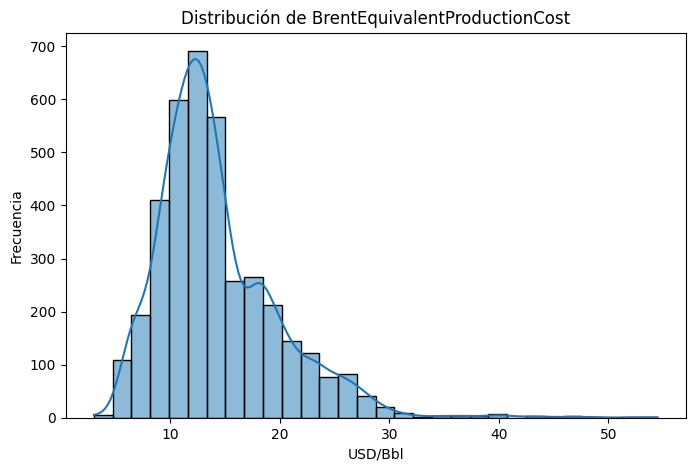

In [19]:
# Histograma de la variable objetivo
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8,5))

sns.histplot(
    df[target],
    bins=30,
    kde=True
)

plt.title("Distribución de BrentEquivalentProductionCost")
plt.xlabel("USD/Bbl")
plt.ylabel("Frecuencia")

plt.show()

c:\LeonellaTP\Miniconda3\envs\ml_venv\lib\site-packages\seaborn\_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):


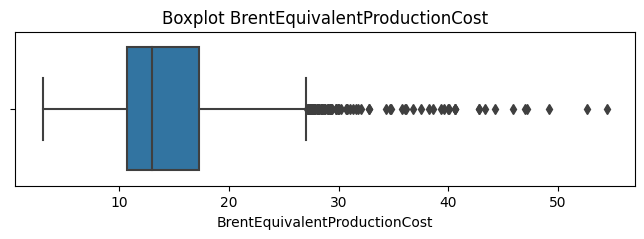

In [20]:
# Boxplot individual de la variable objetivo
plt.figure(figsize=(8,2))

sns.boxplot(
    x=df[target]
)

plt.title("Boxplot BrentEquivalentProductionCost")

plt.show()

In [21]:
# Asimetria de la variable objetivo
df[target].skew()

1.495345542608214

In [22]:
# Curtosis de la variable objetivo
df[target].kurtosis()

4.3409908869154386

### Distribución de la variable objetivo

La distribución de la variable objetivo BrentEquivalentProductionCost presenta una concentración importante de observaciones entre aproximadamente 8 y 20 USD/Bbl.

La media observada es de 14.28 USD/Bbl, mientras que la mediana corresponde a 12.95 USD/Bbl, lo que indica una distribución desplazada hacia valores superiores.

A partir del histograma se observa una distribución unimodal con una cola extendida hacia la derecha, acompañada por un grupo reducido de observaciones con costos considerablemente más altos que la mayoría de la muestra.

### Asimetría

La asimetría calculada fue:

**Skewness = 1.495**

Un valor positivo superior a 1 indica una asimetría positiva moderada a fuerte.

Esto significa que existen activos con costos de producción significativamente superiores al promedio que desplazan la distribución hacia la derecha.

### Curtosis

La curtosis calculada fue:

**Kurtosis = 4.341**

Al ser superior a 3, la distribución presenta características leptocúrticas, es decir, una mayor concentración de observaciones alrededor del centro acompañada por colas relativamente pesadas.

### Valores extremos

El diagrama de caja evidencia la presencia de múltiples observaciones atípicas ubicadas principalmente en la cola superior de la distribución.

Estas observaciones alcanzan valores cercanos a 55 USD/Bbl, muy por encima del tercer cuartil (17.25 USD/Bbl).

Sin embargo, dada la naturaleza del sector Oil & Gas, estos registros pueden corresponder a activos con condiciones geológicas complejas, ubicaciones remotas, proyectos offshore profundos o tecnologías de explotación de alto costo.

Por lo tanto, no se consideran errores evidentes de captura y serán conservados durante las etapas iniciales del análisis.

### Implicaciones para el modelado

La presencia de asimetría positiva, colas pesadas y valores extremos sugiere que la variable objetivo podría beneficiarse de transformaciones como logaritmo o Box-Cox.

La necesidad de aplicar dichas transformaciones será evaluada posteriormente durante la fase de preprocesamiento y validación de modelos.

Adicionalmente, la existencia de valores extremos justifica el uso de métricas robustas como MAE y MAPE junto con RMSE para la evaluación de desempeño.

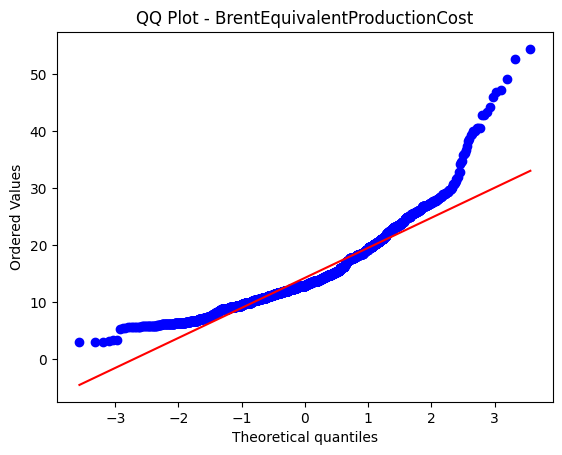

In [23]:
# Probabilidad normal de la variable objetivo
from scipy import stats

stats.probplot(
    df[target].dropna(),
    dist="norm",
    plot=plt
)

plt.title("QQ Plot - BrentEquivalentProductionCost")

plt.show()

### Evaluación de normalidad

El gráfico Q-Q permite comparar la distribución observada de la variable objetivo con una distribución normal teórica.

Se observa que los puntos siguen razonablemente la línea de referencia en la zona central de la distribución; sin embargo, existen desviaciones importantes en ambos extremos, especialmente en la cola superior.

Los cuantiles más altos se separan considerablemente de la recta teórica, indicando la presencia de observaciones extremas y una cola derecha más pesada que la esperada bajo normalidad.

Estos resultados son consistentes con:

- La asimetría positiva observada (Skewness = 1.495).
- La curtosis elevada (Kurtosis = 4.341).
- La presencia de valores atípicos identificados en el boxplot.

Por lo tanto, la variable BrentEquivalentProductionCost no sigue una distribución normal y presenta evidencia de colas pesadas y asimetría hacia la derecha.

### Implicaciones para el modelado

La no normalidad observada sugiere evaluar posteriormente transformaciones como logaritmo o Box-Cox durante la etapa de preprocesamiento.

Asimismo, la presencia de observaciones extremas justifica complementar RMSE con métricas más robustas como MAE y MAPE durante la evaluación de los modelos.

## 2.2 Análisis Unidimensional

### 2.2.1 Variables categóricas

In [24]:
variables_categoricas = [
    "RegionName",
    "CountryName",
    "ReserveTypeName",
    "SupplySubTypeName",
    "ProductionElementName",
    "CostProductionElementName",
    "MemberOpec"
]

df[variables_categoricas].nunique().sort_values(ascending=False)

CostProductionElementName    703
CountryName                   99
ProductionElementName         69
RegionName                    14
SupplySubTypeName              5
ReserveTypeName                2
MemberOpec                     2
dtype: int64

#### Interpretación

Las variables categóricas presentan diferentes niveles de cardinalidad.

La variable con mayor número de categorías es CostProductionElementName, con 703 activos distintos, seguida por CountryName con 99 países y ProductionElementName con 69 agrupaciones operativas.

Las variables RegionName, SupplySubTypeName, ReserveTypeName y MemberOpec presentan cardinalidades moderadas o bajas, lo que facilita su posterior codificación para los modelos de Machine Learning.

La distribución geográfica de la muestra evidencia una mayor representación de:

- North America (1.143 observaciones).
- Africa (747 observaciones).
- Latin America and the Caribbean (563 observaciones).
- Middle East (500 observaciones).
- Northern Europe (468 observaciones).

Asimismo, la base se encuentra compuesta principalmente por activos convencionales (96,34%), mientras que los activos no convencionales representan una proporción significativamente menor (3,66%).

Respecto a la pertenencia a la OPEP, aproximadamente el 79,7% de las observaciones corresponden a activos localizados en países no pertenecientes a la organización.

Estos resultados sugieren que la muestra refleja principalmente activos convencionales ubicados en regiones con amplia actividad petrolera, particularmente Norteamérica, África y Oriente Medio.

### 2.2.2 Variables numéricas

Se analizarán las variables numéricas mediante estadísticos descriptivos y distribuciones con el fin de comprender su comportamiento, dispersión y posibles asimetrías.

In [25]:
variables_numericas = [
    "Year",
    "BrentDifferential",
    "BrentEquivalentProductionCost",
    "WellheadDevelopmentCost",
    "BrentEquivalentDevelopmentCost",
    "WellheadProductionCost",
    "Production"
]

df[variables_numericas].describe().T

,count,mean,std,min,25%,50%,75%,max
Year,4595.0,2018.280740,3.000067,2014.00,2015.00,2018.000,2021.000,2023.00
BrentDifferential,3817.0,3.508756,3.359596,-3.60,1.26,3.000,5.010,25.32
BrentEquivalentProductionCost,3834.0,14.276435,5.538397,3.03,10.68,12.945,17.250,54.47
WellheadDevelopmentCost,3561.0,42.851758,11.164243,12.73,36.15,43.460,50.560,79.00
BrentEquivalentDevelopmentCost,3809.0,46.332221,11.441058,18.63,39.60,46.890,54.240,85.89
WellheadProductionCost,3023.0,10.938806,4.316737,-0.17,8.30,10.580,13.545,38.98
Production,3023.0,188.223592,523.251603,0.00,10.25,37.950,131.240,5901.04


In [26]:
df[variables_numericas].skew()

Year                              0.011423
BrentDifferential                 1.271400
BrentEquivalentProductionCost     1.495346
WellheadDevelopmentCost          -0.188139
BrentEquivalentDevelopmentCost   -0.156582
WellheadProductionCost            0.881227
Production                        6.784209
dtype: float64

In [27]:
df[variables_numericas].kurtosis()

Year                              -1.307854
BrentDifferential                  2.695692
BrentEquivalentProductionCost      4.340991
WellheadDevelopmentCost           -0.083468
BrentEquivalentDevelopmentCost    -0.023440
WellheadProductionCost             2.616178
Production                        58.049384
dtype: float64

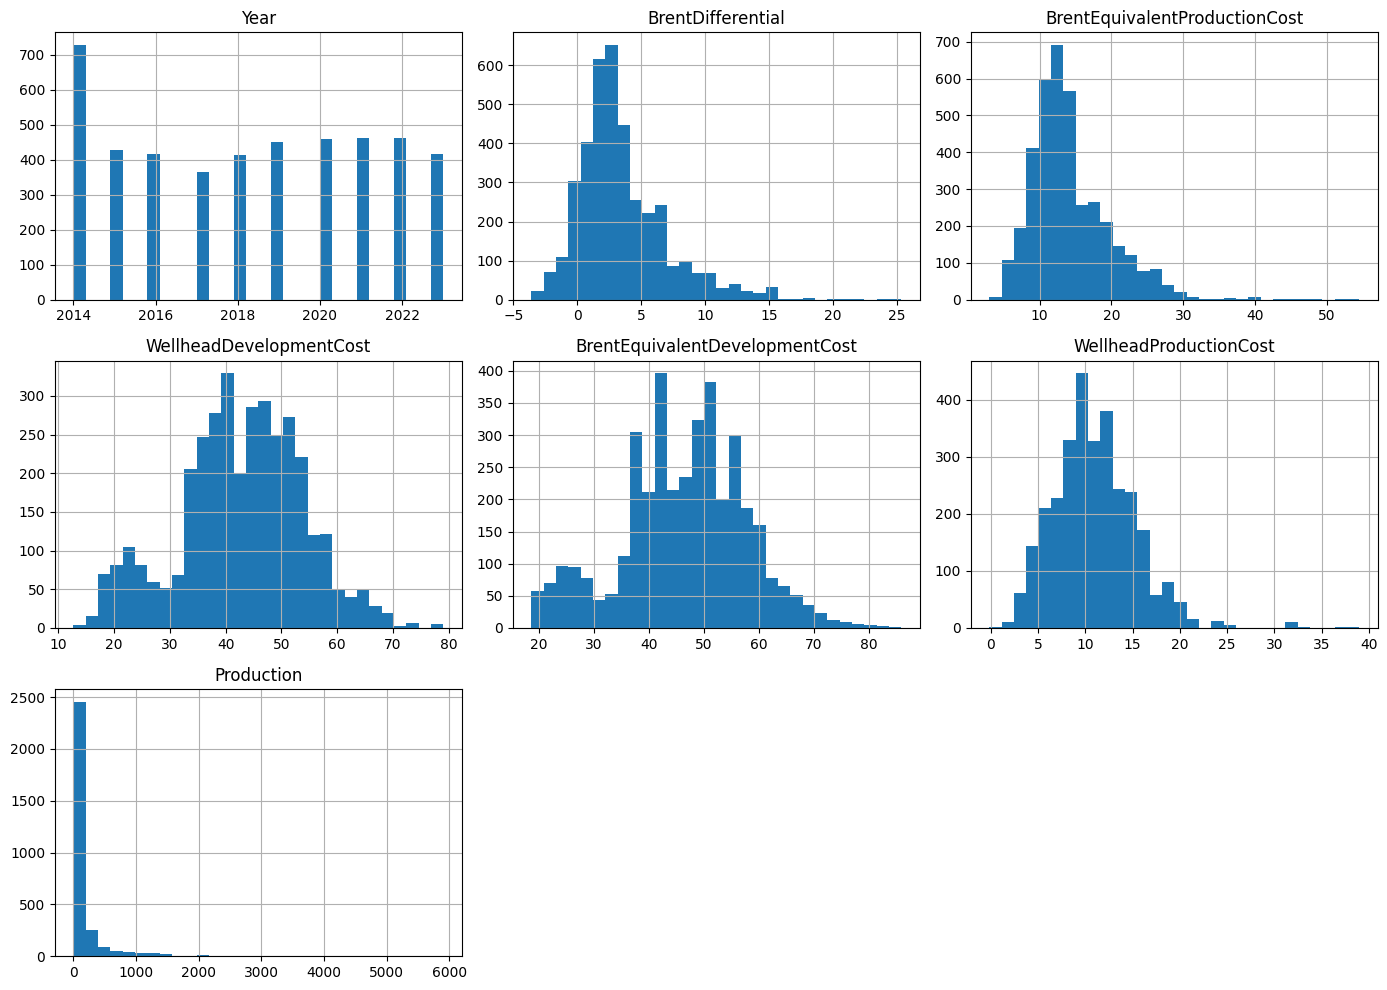

In [28]:
df[variables_numericas].hist(
    figsize=(14,10),
    bins=30
)

plt.tight_layout()
plt.show()

#### Interpretación

Las variables numéricas presentan comportamientos heterogéneos tanto en dispersión como en forma de distribución.

##### Variable temporal

La variable Year presenta una distribución relativamente equilibrada entre 2014 y 2023.

La asimetría es prácticamente nula (0.011), indicando una distribución temporal estable dentro del período analizado.

##### Variables de costos

Las variables:

- BrentEquivalentProductionCost
- WellheadProductionCost
- BrentDifferential

presentan asimetrías positivas, indicando la existencia de activos con costos considerablemente superiores al promedio.

Particularmente:

- BrentEquivalentProductionCost: Skewness = 1.50
- BrentDifferential: Skewness = 1.27
- WellheadProductionCost: Skewness = 0.88

Estas variables presentan colas derechas relativamente extensas y valores extremos consistentes con las diferencias operativas observadas entre activos petroleros a nivel mundial.

##### Variables de desarrollo

WellheadDevelopmentCost y BrentEquivalentDevelopmentCost presentan distribuciones mucho más equilibradas:

- WellheadDevelopmentCost: Skewness = -0.19
- BrentEquivalentDevelopmentCost: Skewness = -0.16

La cercanía a cero indica distribuciones relativamente simétricas y estables.

##### Producción

La variable Production presenta el comportamiento más extremo del conjunto de datos:

- Skewness = 6.78
- Kurtosis = 58.05

La distribución muestra una fuerte concentración de activos con producciones bajas y una pequeña cantidad de activos con producciones extremadamente elevadas.

Este comportamiento es consistente con la estructura real de la industria, donde existen pocos activos gigantes que concentran una proporción importante de la producción mundial.

##### Curtosis

La variable objetivo BrentEquivalentProductionCost presenta:

- Kurtosis = 4.34

lo que indica colas más pesadas que una distribución normal.

Por su parte, Production presenta una curtosis extremadamente elevada (58.05), reflejando una alta presencia de observaciones extremas.

#### Implicaciones para el modelado

Los resultados sugieren:

- Evaluar transformaciones logarítmicas para Production.
- Evaluar transformaciones para BrentEquivalentProductionCost durante el preprocesamiento.
- Utilizar métricas robustas complementarias al RMSE.
- Analizar cuidadosamente la influencia de observaciones extremas durante el modelado.

# 2.3 Análisis Bidimensional

El análisis bidimensional tiene como objetivo identificar relaciones entre pares de variables y comprender cómo las características operativas, económicas y geográficas se relacionan con la variable objetivo.

Siguiendo la guía del proyecto, se evaluarán:

- Relaciones entre variables numéricas.
- Relaciones entre variables categóricas y numéricas.
- Asociaciones entre variables categóricas.
- Relación entre las variables predictoras y la variable objetivo.

Los resultados permitirán identificar patrones lineales y no lineales, posibles problemas de multicolinealidad y variables con capacidad predictiva potencial.

### 2.3.1 Relaciones entre variables numéricas

Se analizarán las relaciones entre las variables numéricas mediante coeficientes de correlación y matrices de calor.

Debido a la presencia de asimetrías y valores extremos identificados en las secciones anteriores, se utilizará inicialmente la correlación de Spearman, la cual resulta más robusta frente a distribuciones no normales.

El objetivo es identificar relaciones monotónicas entre variables y posibles problemas de multicolinealidad.

In [29]:
correlation_matrix = df[
    [
        "BrentDifferential",
        "BrentEquivalentProductionCost",
        "WellheadDevelopmentCost",
        "BrentEquivalentDevelopmentCost",
        "WellheadProductionCost",
        "Production"
    ]
].corr(method="spearman")

correlation_matrix

,BrentDifferential,BrentEquivalentProductionCost,WellheadDevelopmentCost,BrentEquivalentDevelopmentCost,WellheadProductionCost,Production
BrentDifferential,1.000000,0.588999,-0.066603,0.211348,0.070841,0.117481
BrentEquivalentProductionCost,0.588999,1.000000,0.540283,0.722883,0.799666,-0.108374
WellheadDevelopmentCost,-0.066603,0.540283,1.000000,0.943613,0.715352,-0.244195
BrentEquivalentDevelopmentCost,0.211348,0.722883,0.943613,1.000000,0.723382,-0.190443
WellheadProductionCost,0.070841,0.799666,0.715352,0.723382,1.000000,-0.202755
Production,0.117481,-0.108374,-0.244195,-0.190443,-0.202755,1.000000


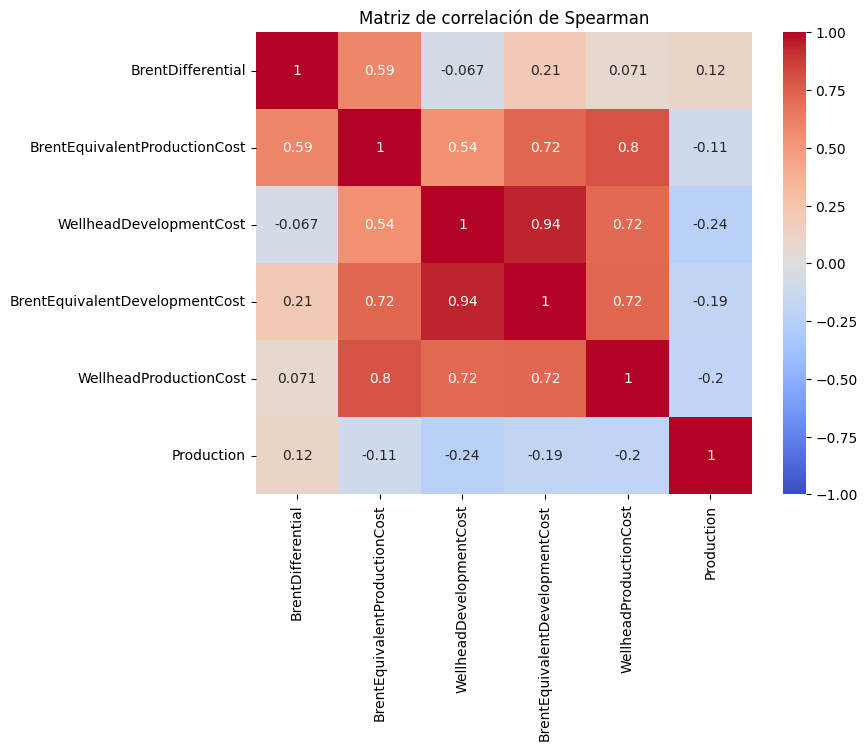

In [30]:
plt.figure(figsize=(8,6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.title("Matriz de correlación de Spearman")

plt.show()

### 2.3.2 Relación entre las variables predictoras y la variable objetivo

En esta etapa se evaluará la asociación entre cada variable numérica y la variable objetivo BrentEquivalentProductionCost.

El objetivo es identificar posibles relaciones lineales o no lineales que puedan contribuir al desarrollo del modelo predictivo.

c:\LeonellaTP\Miniconda3\envs\ml_venv\lib\site-packages\seaborn\_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
c:\LeonellaTP\Miniconda3\envs\ml_venv\lib\site-packages\seaborn\_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
c:\LeonellaTP\Miniconda3\envs\ml_venv\lib\site-packages\seaborn\_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
c:\LeonellaTP\Miniconda3\envs\ml_venv\lib\site-packages\seaborn\_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype

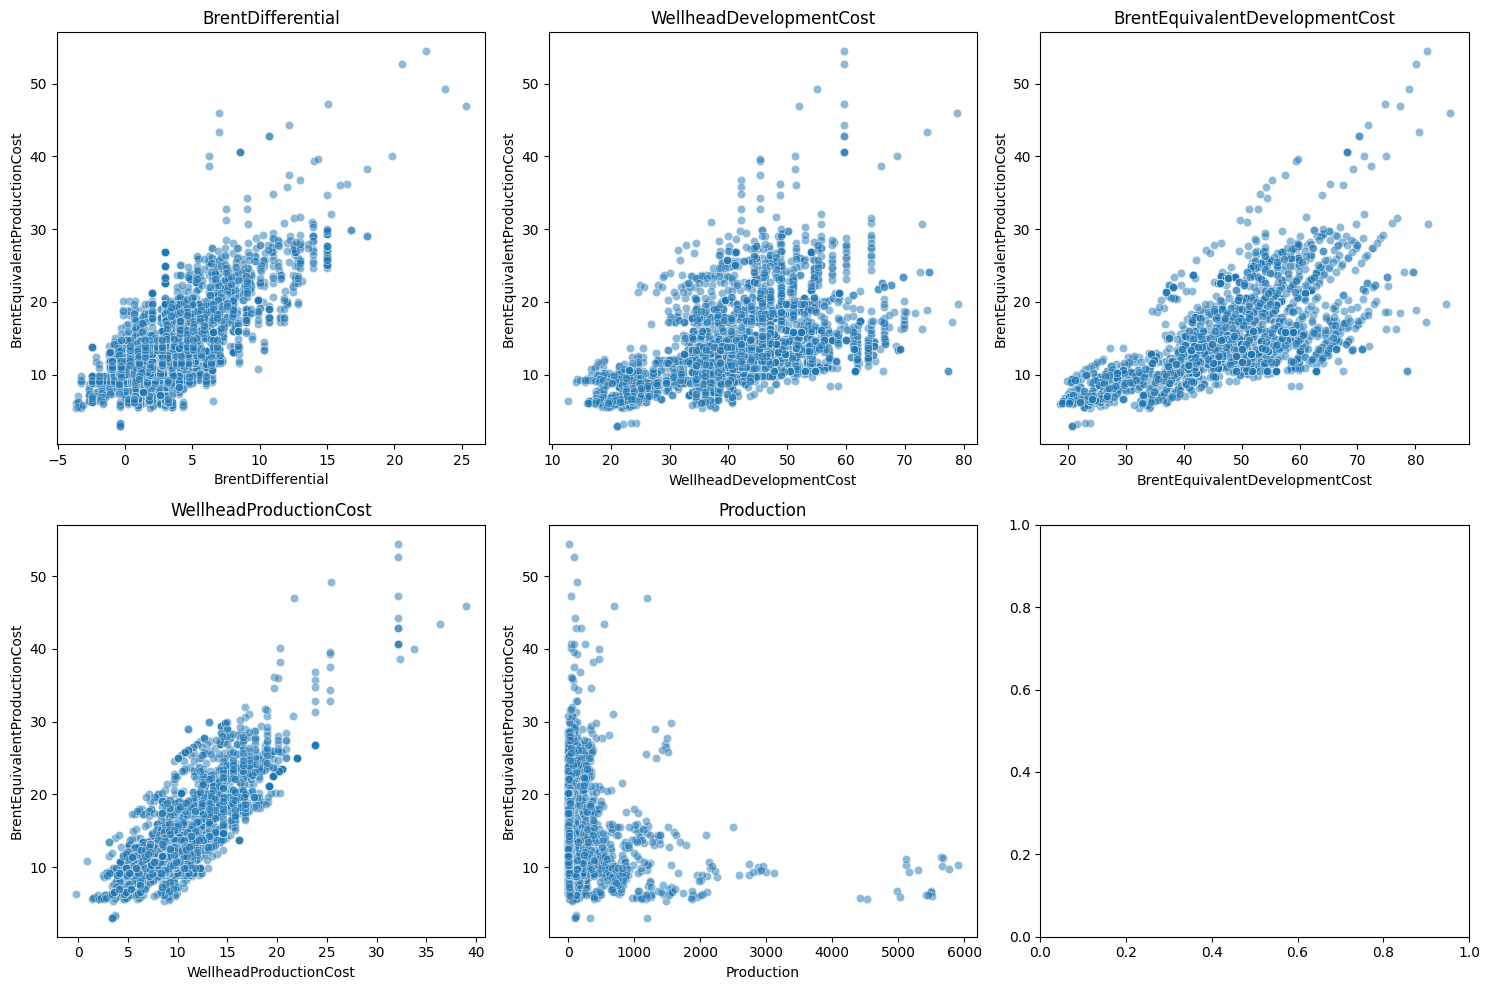

In [31]:
fig, axes = plt.subplots(2,3, figsize=(15,10))

numericas = [
    "BrentDifferential",
    "WellheadDevelopmentCost",
    "BrentEquivalentDevelopmentCost",
    "WellheadProductionCost",
    "Production"
]

for ax, col in zip(axes.flatten(), numericas):
    
    sns.scatterplot(
        data=df,
        x=col,
        y="BrentEquivalentProductionCost",
        alpha=0.5,
        ax=ax
    )
    
    ax.set_title(col)

plt.tight_layout()
plt.show()

#### Interpretación

La matriz de correlación de Spearman permite identificar relaciones monotónicas entre las variables numéricas del dataset.

Las asociaciones más importantes con la variable objetivo BrentEquivalentProductionCost son:

| Variable | Correlación Spearman |
|-----------|-----------:|
| WellheadProductionCost | 0.80 |
| BrentEquivalentDevelopmentCost | 0.72 |
| BrentDifferential | 0.59 |
| WellheadDevelopmentCost | 0.54 |
| Production | -0.11 |

Los resultados indican que WellheadProductionCost es la variable más asociada al comportamiento del BrentEquivalentProductionCost, presentando una correlación positiva fuerte (ρ = 0.80).

Asimismo, BrentEquivalentDevelopmentCost muestra una relación positiva importante (ρ = 0.72), sugiriendo que los activos con mayores costos de desarrollo tienden a presentar mayores costos equivalentes de producción.

La correlación positiva observada con BrentDifferential (ρ = 0.59) indica que las diferencias respecto al precio de referencia Brent también influyen sobre el costo equivalente de producción.

Por el contrario, Production presenta una correlación negativa débil (ρ = -0.11), lo que sugiere que el volumen de producción por sí solo explica una proporción limitada de la variabilidad de la variable objetivo.

### Multicolinealidad preliminar

La matriz de correlación también evidencia relaciones muy altas entre algunas variables predictoras:

- WellheadDevelopmentCost ↔ BrentEquivalentDevelopmentCost: ρ = 0.94
- WellheadProductionCost ↔ BrentEquivalentDevelopmentCost: ρ = 0.72
- WellheadProductionCost ↔ WellheadDevelopmentCost: ρ = 0.72

Estas asociaciones sugieren un posible problema de multicolinealidad que deberá evaluarse posteriormente mediante el cálculo de factores de inflación de la varianza (VIF).

### Evaluación visual

Los diagramas de dispersión muestran relaciones positivas claras entre:

- WellheadProductionCost y BrentEquivalentProductionCost.
- BrentEquivalentDevelopmentCost y BrentEquivalentProductionCost.
- WellheadDevelopmentCost y BrentEquivalentProductionCost.

Estas relaciones parecen ser aproximadamente lineales en gran parte del rango observado, aunque se identifican agrupamientos de observaciones y algunos activos con costos significativamente superiores al promedio.

La variable Production exhibe una dispersión considerable y una relación visual mucho menos evidente con la variable objetivo, lo cual coincide con la baja correlación observada.

### 2.3.2 Variables categóricas frente a la variable objetivo

Se evaluará el comportamiento de BrentEquivalentProductionCost para diferentes categorías mediante diagramas de caja y estadísticas descriptivas.

El objetivo es determinar si existen diferencias significativas entre grupos que puedan aportar capacidad predictiva al modelo.

c:\LeonellaTP\Miniconda3\envs\ml_venv\lib\site-packages\seaborn\_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
c:\LeonellaTP\Miniconda3\envs\ml_venv\lib\site-packages\seaborn\_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
c:\LeonellaTP\Miniconda3\envs\ml_venv\lib\site-packages\seaborn\_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):


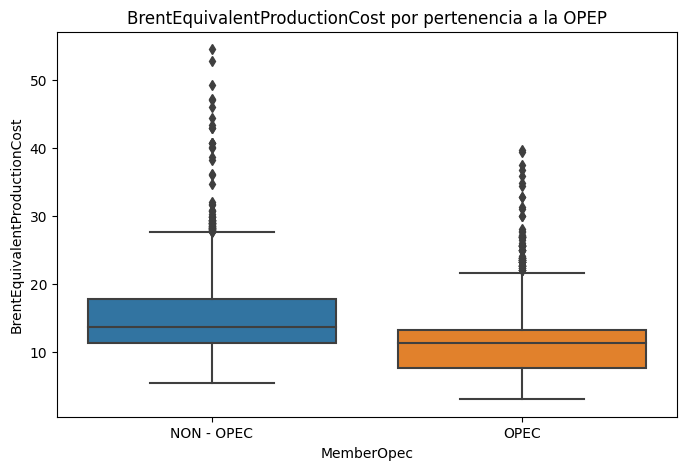

In [32]:
plt.figure(figsize=(8,5))

sns.boxplot(
    data=df,
    x="MemberOpec",
    y="BrentEquivalentProductionCost"
)

plt.title("BrentEquivalentProductionCost por pertenencia a la OPEP")

plt.show()

In [33]:
df.groupby("MemberOpec")[
    "BrentEquivalentProductionCost"
].describe()

,count,mean,std,min,25%,50%,75%,max
MemberOpec,,,,,,,,
NON - OPEC,3034.0,14.882215,5.322343,5.40,11.27,13.71,17.79,54.47
OPEC,800.0,11.979012,5.739453,3.03,7.60,11.23,13.24,39.60


#### Interpretación

Se analizó el comportamiento de la variable objetivo BrentEquivalentProductionCost según la pertenencia o no a la Organización de Países Exportadores de Petróleo (OPEP).

Los estadísticos descriptivos muestran diferencias relevantes entre ambos grupos:

| Grupo | Media (USD/Bbl) | Mediana (USD/Bbl) |
|---------|---------:|---------:|
| NON - OPEC | 14.88 | 13.71 |
| OPEC | 11.98 | 11.23 |

Los activos localizados en países no pertenecientes a la OPEP presentan, en promedio, mayores costos equivalentes de producción que los activos pertenecientes a la organización.

El diagrama de caja evidencia además:

- Una mayor dispersión de los costos en activos NON-OPEC.
- Una mayor presencia de valores extremos superiores dentro del grupo NON-OPEC.
- Una distribución más concentrada en el caso de los activos OPEC.

Desde una perspectiva de negocio, este comportamiento resulta coherente con la estructura de la industria petrolera mundial. Muchos países miembros de la OPEP poseen yacimientos de alta productividad y costos de extracción relativamente bajos, mientras que parte importante de los activos ubicados fuera de la organización corresponden a operaciones offshore complejas, yacimientos maduros o recursos técnicamente más desafiantes.

Estos resultados sugieren que la variable MemberOpec podría aportar capacidad predictiva al modelo y debe mantenerse para los análisis posteriores.

In [34]:
from scipy.stats import mannwhitneyu

non_opec = df[
    df["MemberOpec"] == "NON - OPEC"
]["BrentEquivalentProductionCost"].dropna()

opec = df[
    df["MemberOpec"] == "OPEC"
]["BrentEquivalentProductionCost"].dropna()

stat, p = mannwhitneyu(non_opec, opec)

print("Statistic:", stat)
print("p-value:", p)


Statistic: 1681136.0
p-value: 3.0317843336697184e-63


In [35]:
n1 = len(non_opec)
n2 = len(opec)

u = stat

rank_biserial = 1 - (2*u)/(n1*n2)

print("Rank-biserial correlation:", rank_biserial)

Rank-biserial correlation: -0.3852471984179302


#### Prueba de Mann-Whitney U

Se utilizó la prueba no paramétrica de Mann-Whitney U para comparar los valores de BrentEquivalentProductionCost entre activos localizados en países pertenecientes y no pertenecientes a la OPEP.

**Resultados:**

- Estadístico U = 1.681.136
- p-value = 3.03 × 10⁻⁶³
- Correlación biserial por rangos = -0.385

El valor p obtenido es significativamente inferior al nivel de significancia convencional (α = 0,05), por lo que se rechaza la hipótesis nula de igualdad entre ambos grupos.

Sin embargo, dado el tamaño de la muestra, el análisis no debe basarse únicamente en la significancia estadística. Por esta razón se evaluó adicionalmente el tamaño del efecto mediante la correlación biserial por rangos.

El valor obtenido (|r| = 0,385) indica un efecto de magnitud moderada, sustancialmente menor al observado para ReserveTypeName.

Los resultados sugieren que la pertenencia a la OPEP está asociada con diferencias en el comportamiento del BrentEquivalentProductionCost, aunque el efecto observado es considerablemente menos marcado que el asociado al tipo de reserva.

Este hallazgo es consistente con las estadísticas descriptivas previamente obtenidas, donde los activos NON-OPEC presentaban mayores costos promedio (14,88 USD/Bbl) que los activos OPEC (11,98 USD/Bbl).

Por lo tanto, la variable MemberOpec conserva capacidad explicativa y será mantenida para las etapas posteriores de modelado.

c:\LeonellaTP\Miniconda3\envs\ml_venv\lib\site-packages\seaborn\_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
c:\LeonellaTP\Miniconda3\envs\ml_venv\lib\site-packages\seaborn\_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
c:\LeonellaTP\Miniconda3\envs\ml_venv\lib\site-packages\seaborn\_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):


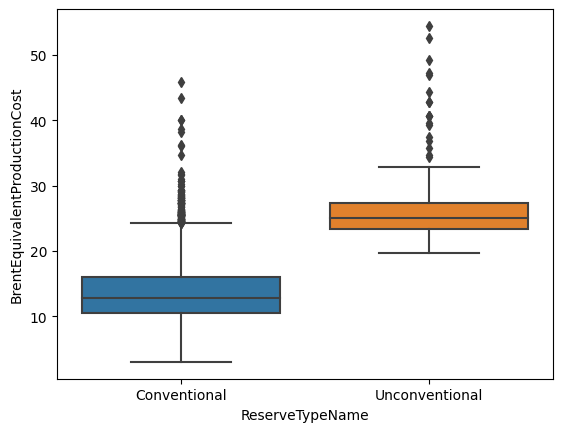

In [36]:
sns.boxplot(
    data=df,
    x="ReserveTypeName",
    y="BrentEquivalentProductionCost"
)

plt.show()

In [37]:
df.groupby("ReserveTypeName")[
    "BrentEquivalentProductionCost"
].describe()

,count,mean,std,min,25%,50%,75%,max
ReserveTypeName,,,,,,,,
Conventional,3684.0,13.750790,4.818975,3.03,10.5700,12.83,16.0600,45.95
Unconventional,150.0,27.186267,6.359925,19.71,23.3075,25.02,27.4125,54.47


#### Interpretación

Se evaluó el comportamiento de la variable objetivo BrentEquivalentProductionCost según el tipo de reserva.

Los resultados muestran diferencias importantes entre activos convencionales y no convencionales:

| Tipo de reserva | Media (USD/Bbl) | Mediana (USD/Bbl) |
|-----------------|----------------:|------------------:|
| Conventional | 13.75 | 12.83 |
| Unconventional | 27.19 | 25.02 |

Los activos no convencionales presentan costos equivalentes de producción significativamente superiores a los activos convencionales.

La diferencia entre las medianas supera los 12 USD/Bbl, lo que sugiere una separación estructural entre ambos grupos.

El diagrama de caja evidencia además que:

- Los activos no convencionales mantienen valores centrales considerablemente más altos.
- Existe una dispersión relativamente elevada en ambos grupos.
- Los activos convencionales presentan una mayor cantidad de observaciones extremas debido a su mayor representación dentro del dataset.

Desde una perspectiva de negocio, este resultado es consistente con la realidad de la industria petrolera, ya que los recursos no convencionales suelen requerir tecnologías más complejas, mayores inversiones y procesos de extracción más costosos.

Por tanto, la variable ReserveTypeName parece tener una capacidad explicativa importante sobre el comportamiento del BrentEquivalentProductionCost y debería conservarse para las etapas posteriores de modelado.

In [38]:
from scipy.stats import mannwhitneyu

In [39]:
conv = df[
    df["ReserveTypeName"]=="Conventional"
]["BrentEquivalentProductionCost"].dropna()

unconv = df[
    df["ReserveTypeName"]=="Unconventional"
]["BrentEquivalentProductionCost"].dropna()

stat, p = mannwhitneyu(conv, unconv)

print("Statistic:", stat)
print("p-value:", p)

Statistic: 16103.5
p-value: 2.2962733644238375e-85


#### Prueba de Mann-Whitney U

Debido a que la variable objetivo no sigue una distribución normal y presenta asimetría positiva, colas pesadas y valores atípicos, se utilizó la prueba no paramétrica de Mann-Whitney U para comparar los costos equivalentes de producción entre activos convencionales y no convencionales.

**Resultados:**

- Estadístico U = 16.103,5
- p-value = 2,30 × 10⁻⁸⁵
- Correlación biserial por rangos = 0,94

El valor p obtenido es considerablemente inferior al nivel de significancia convencional (α = 0,05), por lo que se rechaza la hipótesis nula de igualdad entre grupos.

Sin embargo, dado el tamaño de la muestra, el valor p por sí solo no es suficiente para evaluar la magnitud de la diferencia. Por este motivo se calculó adicionalmente el tamaño del efecto mediante la correlación biserial por rangos.

El valor obtenido (r = 0,94) indica un efecto extremadamente grande, lo que sugiere una separación muy marcada entre los costos asociados a activos convencionales y no convencionales.

Este resultado confirma que la variable ReserveTypeName posee una capacidad explicativa importante respecto al comportamiento de la variable objetivo BrentEquivalentProductionCost.

Por tanto, la variable debe conservarse para las etapas posteriores de modelado.

In [40]:
n1 = len(conv)
n2 = len(unconv)

u = stat

rank_biserial = 1 - (2*u)/(n1*n2)

print("Rank-biserial correlation:", rank_biserial)

Rank-biserial correlation: 0.9417173362287369


### Consideración sobre significancia estadística

Debido al tamaño de la muestra, se reportarán conjuntamente valores p y tamaños de efecto, siguiendo las recomendaciones de la guía del proyecto.

La significancia estadística será complementada con métricas que permitan evaluar la relevancia práctica de las diferencias observadas.

c:\LeonellaTP\Miniconda3\envs\ml_venv\lib\site-packages\seaborn\_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
c:\LeonellaTP\Miniconda3\envs\ml_venv\lib\site-packages\seaborn\_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
c:\LeonellaTP\Miniconda3\envs\ml_venv\lib\site-packages\seaborn\_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):


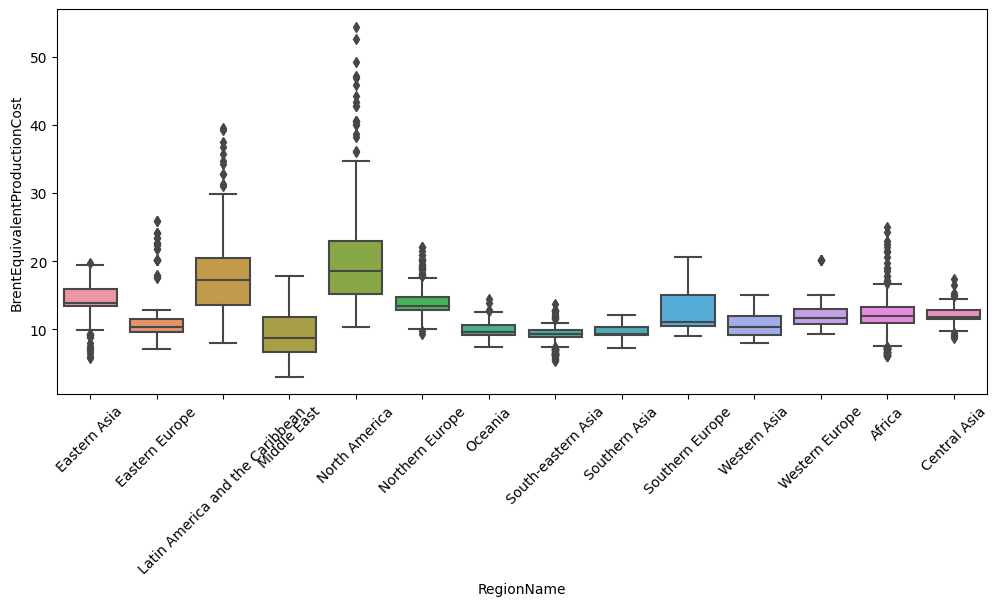

In [41]:
plt.figure(figsize=(12,5))

sns.boxplot(
    data=df,
    x="RegionName",
    y="BrentEquivalentProductionCost"
)

plt.xticks(rotation=45)

plt.show()

### Influencia de la región geográfica sobre la variable objetivo

Se analizó el comportamiento de BrentEquivalentProductionCost entre las diferentes regiones geográficas representadas en el dataset.

Debido a que existen múltiples grupos y la variable objetivo no sigue una distribución normal, se utilizará la prueba no paramétrica de Kruskal-Wallis.

In [42]:
from scipy.stats import kruskal

grupos = [
    g["BrentEquivalentProductionCost"].dropna().values
    for _, g in df.groupby("RegionName")
]

stat, p = kruskal(*grupos)

print("Statistic:", stat)
print("p-value:", p)


Statistic: 2291.8899825150406
p-value: 0.0


#### Prueba de Kruskal-Wallis

Debido a que la variable objetivo no sigue una distribución normal y la variable RegionName contiene múltiples grupos geográficos, se utilizó la prueba no paramétrica de Kruskal-Wallis para evaluar si existen diferencias en la distribución de BrentEquivalentProductionCost entre regiones.

**Resultados:**

- Estadístico H = 2291.89
- p-value < 0.001

El valor p obtenido es extremadamente pequeño, por lo que se rechaza la hipótesis nula de igualdad entre las distribuciones de todas las regiones analizadas.

Existe evidencia estadísticamente significativa de que el comportamiento del BrentEquivalentProductionCost varía entre regiones geográficas.

La inspección visual de los diagramas de caja muestra diferencias importantes entre regiones. Por ejemplo:

- North America presenta algunos de los costos equivalentes de producción más elevados y una mayor dispersión.
- Middle East concentra los costos medianos más bajos.
- Oceania, Eastern Europe y Southern Asia presentan distribuciones relativamente más compactas.
- Africa muestra una elevada variabilidad y una presencia importante de valores extremos.

Estos resultados sugieren que los factores geográficos y regionales influyen significativamente sobre los costos de producción de los activos upstream y que la variable RegionName debe conservarse para el modelado posterior.

### Evaluación de multicolinealidad

Se evaluará la existencia de relaciones excesivamente fuertes entre variables predictoras mediante el cálculo del Variance Inflation Factor (VIF).

La multicolinealidad puede afectar la estabilidad e interpretación de los modelos de regresión.

In [43]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
import pandas as pd

X_vif = df[
    [
        "BrentDifferential",
        "WellheadDevelopmentCost",
        "BrentEquivalentDevelopmentCost",
        "WellheadProductionCost",
        "Production"
    ]
].dropna()

vif = pd.DataFrame()
vif["Variable"] = X_vif.columns
vif["VIF"] = [
    variance_inflation_factor(X_vif.values, i)
    for i in range(X_vif.shape[1])
]

vif.sort_values("VIF", ascending=False)

,Variable,VIF
2,BrentEquivalentDevelopmentCost,1.530333e+09
1,WellheadDevelopmentCost,1.298030e+09
0,BrentDifferential,1.789834e+07
3,WellheadProductionCost,1.497463e+01
4,Production,1.097956e+00


#### Evaluación de multicolinealidad mediante VIF

Se calculó el Variance Inflation Factor (VIF) para evaluar la presencia de multicolinealidad entre las variables numéricas predictoras.

Los resultados obtenidos fueron:

| Variable | VIF |
|-----------|-----------:|
| BrentEquivalentDevelopmentCost | 1.53 × 10⁹ |
| WellheadDevelopmentCost | 1.30 × 10⁹ |
| BrentDifferential | 1.79 × 10⁷ |
| WellheadProductionCost | 14.97 |
| Production | 1.10 |

La literatura suele considerar:

- VIF < 5: baja multicolinealidad.
- 5 ≤ VIF < 10: multicolinealidad moderada.
- VIF ≥ 10: multicolinealidad problemática.

Los resultados muestran una multicolinealidad extremadamente elevada entre las variables:

- WellheadDevelopmentCost
- BrentEquivalentDevelopmentCost

Este resultado es consistente con la matriz de correlación de Spearman, donde ambas variables presentaron una correlación de 0.94.

Asimismo, WellheadProductionCost presenta un VIF cercano a 15, indicando también una relación importante con otras variables económicas del modelo.

Por el contrario, la variable Production presenta un VIF cercano a 1, indicando independencia relativa respecto al resto de variables numéricas.

#### Implicaciones para el modelado

La evidencia sugiere que WellheadDevelopmentCost y BrentEquivalentDevelopmentCost contienen información altamente redundante.

Por tanto, durante la etapa de construcción del modelo será necesario evaluar:

- Eliminación de una de las variables redundantes.
- Selección basada en conocimiento de negocio.
- Uso de modelos menos sensibles a la multicolinealidad.
- Técnicas de reducción de dimensionalidad.

La multicolinealidad identificada debe considerarse especialmente si se utilizan modelos lineales o interpretables.

## 2.4 Análisis Multivariado

El análisis multivariado tiene como objetivo identificar estructuras latentes, relaciones complejas entre variables y posibles redundancias dentro del conjunto de datos.

Inicialmente se aplicará un Análisis de Componentes Principales (PCA) para evaluar la dimensionalidad efectiva de las variables numéricas.

In [44]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

X_pca = df[
    [
        "BrentDifferential",
        "WellheadDevelopmentCost",
        "BrentEquivalentDevelopmentCost",
        "WellheadProductionCost",
        "Production"
    ]
].dropna()

X_scaled = StandardScaler().fit_transform(X_pca)

pca = PCA()

pca.fit(X_scaled)

explained_variance = pca.explained_variance_ratio_

explained_variance

array([5.46665249e-01, 2.15048965e-01, 1.62680876e-01, 7.56049095e-02,
       1.03760228e-09])

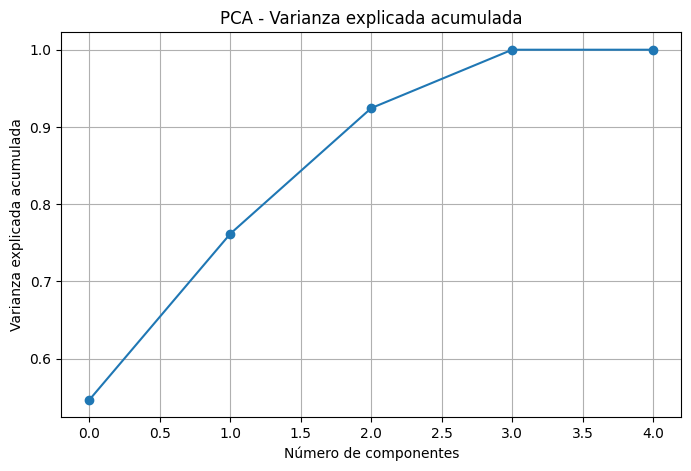

In [45]:
import numpy as np

plt.figure(figsize=(8,5))

plt.plot(
    np.cumsum(explained_variance),
    marker="o"
)

plt.xlabel("Número de componentes")
plt.ylabel("Varianza explicada acumulada")

plt.title("PCA - Varianza explicada acumulada")

plt.grid(True)

plt.show()

### Análisis de Componentes Principales (PCA)

Se aplicó un Análisis de Componentes Principales (PCA) sobre las variables numéricas con el objetivo de evaluar la dimensionalidad efectiva del conjunto de datos y detectar posibles redundancias entre variables.

Los porcentajes de varianza explicada por cada componente fueron:

| Componente | Varianza explicada |
|------------|-------------------:|
| PC1 | 54.67% |
| PC2 | 21.50% |
| PC3 | 16.27% |
| PC4 | 7.56% |
| PC5 | ≈ 0% |

La varianza acumulada muestra que:

- El primer componente explica aproximadamente el 54.7% de la variabilidad total.
- Los dos primeros componentes explican el 76.2%.
- Los tres primeros componentes explican el 92.4%.
- A partir del cuarto componente se alcanza prácticamente el 100% de la variabilidad observada.

#### Interpretación

Los resultados sugieren una fuerte redundancia entre las variables numéricas incluidas en el análisis.

La necesidad de únicamente tres componentes para explicar más del 90% de la varianza total es consistente con la evidencia encontrada previamente en la evaluación de multicolinealidad.

Particularmente, las variables:

- WellheadDevelopmentCost
- BrentEquivalentDevelopmentCost
- WellheadProductionCost

presentan una elevada correlación y aportan información parcialmente redundante.

Por el contrario, la variable Production parece aportar una dimensión diferente al resto de variables de costos, lo que coincide con los bajos niveles de correlación observados previamente.

#### Implicaciones para el modelado

El PCA confirma la existencia de redundancia entre varias variables económicas.

Durante la etapa de modelado se evaluará:

- Eliminación de variables altamente correlacionadas.
- Selección basada en conocimiento de negocio.
- Uso de PCA como técnica alternativa de reducción de dimensionalidad.
- Comparación entre modelos con variables originales y modelos con variables transformadas.

Los resultados obtenidos sugieren que la dimensionalidad efectiva del conjunto de variables numéricas es considerablemente menor que el número total de variables disponibles.

### Detección de outliers multivariados mediante Isolation Forest

In [46]:
from sklearn.ensemble import IsolationForest

X_iso = X_scaled

iso = IsolationForest(
    contamination=0.02,
    random_state=42
)

outliers = iso.fit_predict(X_iso)

pd.Series(outliers).value_counts()


 1    2962
-1      61
Name: count, dtype: int64

### Detección de outliers multivariados mediante Isolation Forest

Se aplicó el algoritmo Isolation Forest sobre las variables numéricas estandarizadas con el objetivo de detectar observaciones atípicas considerando simultáneamente múltiples dimensiones.

A diferencia de los análisis univariados realizados previamente mediante boxplots, este procedimiento permite identificar observaciones inusuales por la combinación conjunta de sus características.

#### Resultados

| Clasificación | Cantidad |
|---------------|---------:|
| Observaciones normales | 2.962 |
| Outliers multivariados | 61 |

Bajo un nivel de contaminación del 2%, el algoritmo identificó 61 observaciones potencialmente atípicas, equivalentes aproximadamente al 2% de la muestra analizada.

#### Interpretación

La proporción de observaciones clasificadas como anómalas es reducida en comparación con el tamaño total de la muestra.

Dado el contexto de la industria Oil & Gas, la presencia de outliers multivariados no implica necesariamente errores de captura o medición. Es probable que varios de estos registros correspondan a:

- Activos de producción excepcionalmente alta.
- Proyectos offshore complejos.
- Recursos no convencionales.
- Campos con costos de desarrollo significativamente superiores al promedio.

Por esta razón, las observaciones identificadas no serán eliminadas automáticamente. Su tratamiento será evaluado posteriormente durante la etapa de modelado y validación.

La existencia de estos registros refuerza además los hallazgos obtenidos en los análisis univariados, donde se observaron distribuciones asimétricas y colas pesadas en varias variables económicas y operativas.

### Estructura de grupos y subpoblaciones

Se realizará un análisis exploratorio de agrupamiento para identificar posibles subpoblaciones dentro del conjunto de activos petroleros.

In [47]:
from sklearn.cluster import KMeans

pca_2 = PCA(n_components=2)
X_2d = pca_2.fit_transform(X_scaled)

kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

clusters = kmeans.fit_predict(X_scaled)

c:\LeonellaTP\Miniconda3\envs\ml_venv\lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] El sistema no puede encontrar el archivo especificado
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\LeonellaTP\Miniconda3\envs\ml_venv\lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
  File "c:\LeonellaTP\Miniconda3\envs\ml_venv\lib\subprocess.py", line 505, in run
    with Popen(*popenargs, **kwargs) as process:
  File "c:\LeonellaTP\Miniconda3\envs\ml_venv\lib\subprocess.py", line 951, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "c:\LeonellaTP\Miniconda3\envs\ml_venv\lib\subprocess.py", line 1436, in _execute_child
    hp, ht, pid, tid = _winapi.C

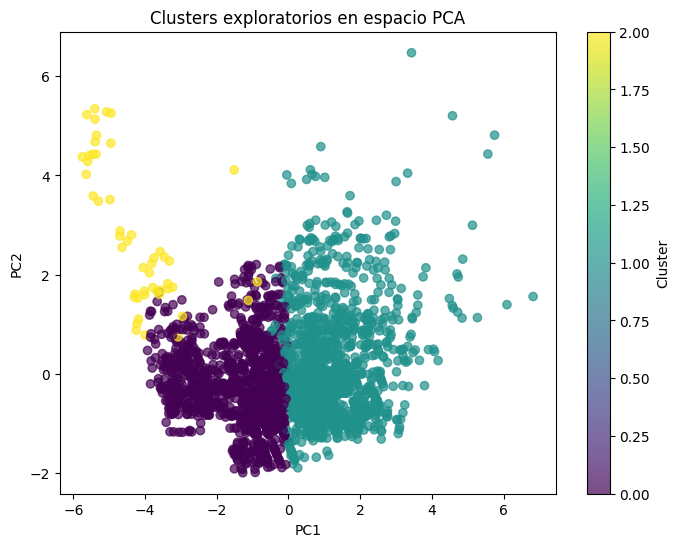

In [48]:
plt.figure(figsize=(8,6))

plt.scatter(
    X_2d[:,0],
    X_2d[:,1],
    c=clusters,
    cmap="viridis",
    alpha=0.7
)

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("Clusters exploratorios en espacio PCA")

plt.colorbar(label="Cluster")

plt.show()

### Estructura de grupos y subpoblaciones

Con el fin de explorar la posible existencia de subpoblaciones dentro del conjunto de datos, se aplicó el algoritmo K-Means utilizando tres grupos y posteriormente se proyectaron las observaciones sobre las dos primeras componentes principales obtenidas mediante PCA.

#### Interpretación

La visualización muestra la existencia de tres agrupamientos diferenciados dentro del espacio multivariado.

Se observa una separación clara entre los grupos en la dirección de la primera componente principal (PC1), lo que sugiere que una combinación de variables económicas y operativas genera patrones diferenciados entre los activos analizados.

Asimismo, se identifica un grupo más compacto localizado en la zona izquierda del gráfico, mientras que los otros dos grupos presentan una mayor dispersión y heterogeneidad.

Estos resultados sugieren que la muestra no es completamente homogénea y que existen subpoblaciones con características operativas y económicas distintas.

Desde una perspectiva de negocio, estos agrupamientos podrían estar asociados a diferencias entre:

- Activos convencionales y no convencionales.
- Regiones geográficas.
- Escalas de producción.
- Estructuras de costos de desarrollo y producción.

No obstante, dado que el objetivo principal del proyecto es la predicción y no la segmentación, este análisis se utiliza únicamente con fines exploratorios.

#### Dimensionalidad efectiva

Los resultados del PCA y del agrupamiento confirman que la estructura del dataset puede describirse mediante un número reducido de componentes latentes sin perder una proporción importante de la información original.

Esto refuerza la evidencia previamente observada sobre la existencia de redundancia entre varias variables de costos.


## 2.5 Auditoría de Fuga de Datos (Data Leakage)

Una condición fundamental para el desarrollo de modelos predictivos confiables consiste en garantizar que las variables explicativas estén disponibles en el momento en que se realiza la predicción y que no incorporen información derivada directa o indirectamente de la variable objetivo.

En esta sección se evalúan posibles riesgos de fuga de información, variables altamente correlacionadas con la variable objetivo y potenciales proxies que podrían producir estimaciones artificialmente optimistas.

### Disponibilidad de las variables al momento de la predicción

Se revisó conceptualmente cada variable empleada en el estudio para determinar si estaría disponible al momento de generar una estimación del BrentEquivalentProductionCost.

| Variable | ¿Disponible al momento de predecir? | Riesgo |
|-----------|-----------|-----------|
| RegionName | Sí | Bajo |
| CountryName | Sí | Bajo |
| ReserveTypeName | Sí | Bajo |
| SupplyTypeName | Sí | Bajo |
| SupplySubTypeName | Sí | Bajo |
| ReserveLocationName | Sí | Bajo |
| ProductionElementName | Sí | Bajo |
| MemberOpec | Sí | Bajo |
| Year | Sí | Bajo |
| Production | Depende del escenario | Medio |
| BrentDifferential | Depende del escenario | Medio |
| WellheadProductionCost | Riesgo potencial | Alto |
| WellheadDevelopmentCost | Riesgo potencial | Alto |
| BrentEquivalentDevelopmentCost | Riesgo potencial | Alto |

#### Interpretación

Las variables geográficas, operativas y temporales no presentan evidencia de fuga de información, ya que corresponden a características estructurales conocidas del activo.

Sin embargo, las variables WellheadProductionCost, WellheadDevelopmentCost y BrentEquivalentDevelopmentCost representan indicadores económicos estrechamente relacionados con la variable objetivo BrentEquivalentProductionCost.

Por esta razón, estas variables requieren una evaluación adicional durante el proceso de modelado.

### Variables potencialmente proxy de la variable objetivo

#### Interpretación

Se identificaron varias variables con asociaciones elevadas respecto a la variable objetivo.

| Variable | Correlación Spearman |
|-----------|-----------:|
| WellheadProductionCost | 0.80 |
| BrentEquivalentDevelopmentCost | 0.72 |
| WellheadDevelopmentCost | 0.54 |

Las correlaciones observadas indican que estas variables contienen información estrechamente relacionada con la estructura de costos del activo.

Adicionalmente, los análisis de PCA y VIF mostraron importantes niveles de redundancia entre estas variables.

Aunque no existe evidencia directa de que correspondan a una transformación matemática inmediata de la variable objetivo, sí pueden comportarse como proxies parciales del costo equivalente de producción.

En consecuencia, durante el modelado se evaluará el desempeño del modelo tanto con estas variables incluidas como excluidas.

#### Multicolinealidad

El análisis de VIF identificó niveles extremadamente elevados de multicolinealidad entre:

- WellheadDevelopmentCost
- BrentEquivalentDevelopmentCost

Lo anterior sugiere que ambas variables contienen información altamente redundante.

Por esta razón, la selección final de variables deberá considerar la eliminación de algunas de ellas o el uso de técnicas de reducción de dimensionalidad.

In [49]:
# validacion de entidades repetidas
df["CostProductionElementName"].nunique()

703

#### Entidades repetidas

El dataset contiene 703 activos distintos observados durante múltiples años.

Por tanto, diferentes observaciones corresponden a la misma entidad física en distintos momentos del tiempo.

Esta característica implica que una partición aleatoria convencional podría introducir fugas de información entre entrenamiento y prueba.

Por esta razón, las estrategias de validación deberán considerar explícitamente la estructura longitudinal de los datos.

## 2.6 Componente Temporal

El dataset contiene una dimensión temporal asociada a la variable Year, con observaciones comprendidas entre 2014 y 2023.

Aunque el problema principal corresponde a una regresión sobre datos de panel, resulta relevante analizar la evolución temporal de la variable objetivo para identificar tendencias, posibles cambios estructurales y riesgos de deriva temporal.

### Comportamiento temporal de la variable objetivo


c:\LeonellaTP\Miniconda3\envs\ml_venv\lib\site-packages\seaborn\_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
c:\LeonellaTP\Miniconda3\envs\ml_venv\lib\site-packages\seaborn\_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
c:\LeonellaTP\Miniconda3\envs\ml_venv\lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
c:\LeonellaTP\Miniconda3\envs\ml_venv\lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert in

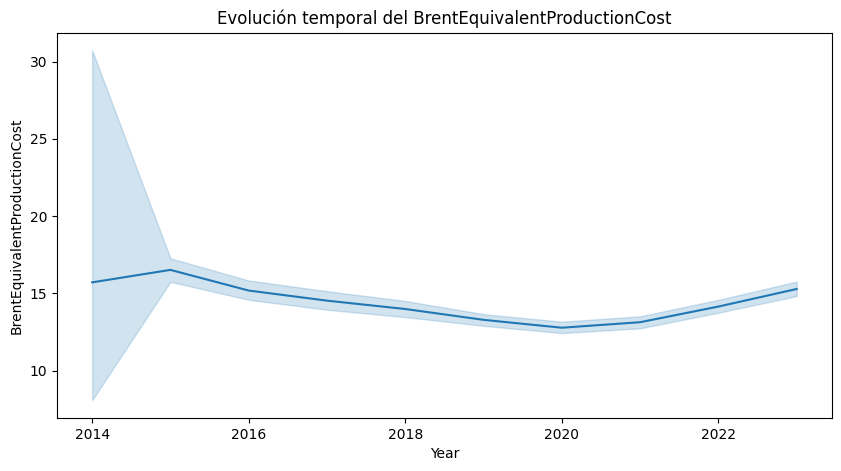

In [50]:
plt.figure(figsize=(10,5))

sns.lineplot(
    data=df,
    x="Year",
    y="BrentEquivalentProductionCost"
)

plt.title("Evolución temporal del BrentEquivalentProductionCost")
plt.show()

In [51]:
df.groupby("Year")[
    "BrentEquivalentProductionCost"
].mean()

Year
2014    15.710000
2015    16.518551
2016    15.180412
2017    14.526492
2018    13.985196
2019    13.284238
2020    12.774207
2021    13.131160
2022    14.143720
2023    15.282010
Name: BrentEquivalentProductionCost, dtype: float64

### Evolución temporal del BrentEquivalentProductionCost

Se calculó el valor promedio anual de BrentEquivalentProductionCost para evaluar la evolución del costo equivalente de producción durante el período analizado.

#### Interpretación

Los resultados muestran un comportamiento no estacionario a lo largo del horizonte temporal.

La variable objetivo presenta una fase descendente entre 2015 y 2020:

- 2015: 16.52 USD/Bbl
- 2016: 15.18 USD/Bbl
- 2017: 14.53 USD/Bbl
- 2018: 13.99 USD/Bbl
- 2019: 13.28 USD/Bbl
- 2020: 12.77 USD/Bbl

Posteriormente se observa un cambio de tendencia:

- 2021: 13.13 USD/Bbl
- 2022: 14.14 USD/Bbl
- 2023: 15.28 USD/Bbl

La trayectoria sugiere una reducción progresiva de costos hasta 2020 seguida de una recuperación entre 2021 y 2023.

Este comportamiento podría estar asociado a factores macroeconómicos, cambios en las condiciones del mercado petrolero, modificaciones en las estrategias de inversión o alteraciones en las estructuras globales de costos del sector.

La presencia de una tendencia temporal indica que la variable Year contiene información potencialmente relevante para el modelo predictivo y no debería descartarse sin una evaluación adicional.

#### Implicaciones para el modelado

La evidencia observada sugiere la existencia de dependencia temporal moderada.

Por esta razón se mantendrá la variable Year dentro del conjunto inicial de variables predictoras.

Adicionalmente, durante la etapa de validación se deberá considerar que un mismo activo aparece en múltiples años, evitando estrategias de partición que puedan introducir fuga temporal de información.

## 2.8 Componente Espacio-Temporal

El dataset presenta simultáneamente una dimensión geográfica y una dimensión temporal.

La dimensión espacial se encuentra representada mediante las variables RegionName y CountryName, mientras que la dimensión temporal se encuentra representada por la variable Year con observaciones comprendidas entre 2014 y 2023.

Dado que la base de datos no contiene coordenadas geográficas explícitas (latitud y longitud), el análisis espacio-temporal se realiza a un nivel agregado de regiones y países.

c:\LeonellaTP\Miniconda3\envs\ml_venv\lib\site-packages\seaborn\_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
c:\LeonellaTP\Miniconda3\envs\ml_venv\lib\site-packages\seaborn\_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
c:\LeonellaTP\Miniconda3\envs\ml_venv\lib\site-packages\seaborn\_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
c:\LeonellaTP\Miniconda3\envs\ml_venv\lib\site-packages\seaborn\_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype

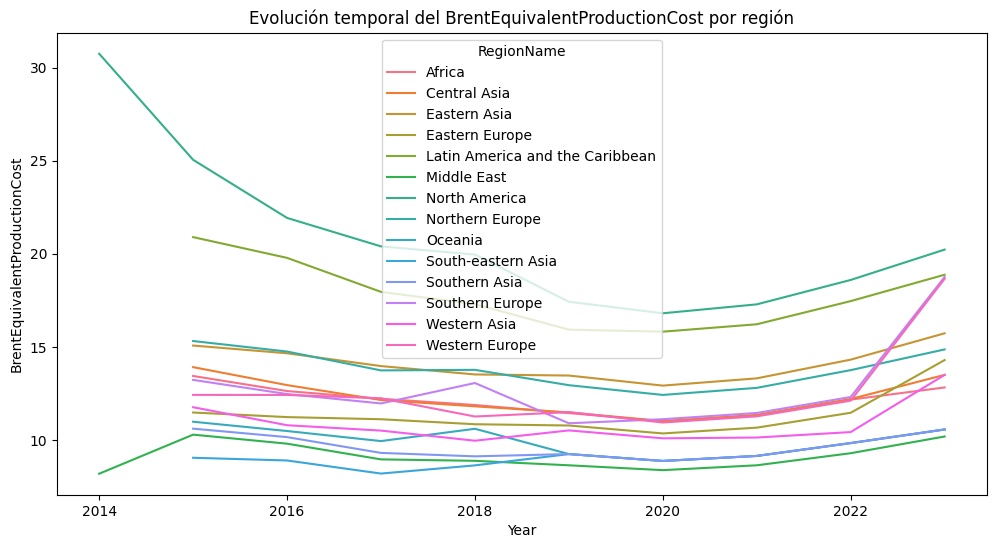

In [52]:
regional_year = (
    df.groupby(
        ["Year","RegionName"]
    )["BrentEquivalentProductionCost"]
    .mean()
    .reset_index()
)

plt.figure(figsize=(12,6))

sns.lineplot(
    data=regional_year,
    x="Year",
    y="BrentEquivalentProductionCost",
    hue="RegionName"
)

plt.title(
    "Evolución temporal del BrentEquivalentProductionCost por región"
)

plt.show()

### Evolución temporal por región

La evolución temporal de los costos equivalentes de producción muestra comportamientos diferenciados entre regiones.

Algunas regiones presentan niveles históricamente bajos de costo de producción, mientras que otras evidencian estructuras de costos más elevadas.

La existencia de trayectorias temporales diferenciadas sugiere que factores geográficos y regionales influyen sobre la dinámica temporal del BrentEquivalentProductionCost.

### Interacción espacio-tiempo

La evidencia observada indica que la evolución temporal del BrentEquivalentProductionCost no es homogénea entre regiones.

Las diferencias entre regiones persisten a lo largo del período analizado y sugieren la presencia de estructuras de costos particulares asociadas a características geográficas, geológicas y operativas de cada zona productora.

No se identificó evidencia suficiente para afirmar desplazamientos espaciales o aparición de nuevos hotspots debido a la ausencia de coordenadas geográficas detalladas.

Debido a la ausencia de coordenadas geográficas explícitas, no fue posible realizar análisis de autocorrelación espacial, indicadores de Moran, LISA, hotspots o particiones por bloques espaciales descritas en la guía metodológica. El análisis espacio-temporal se limita a la información geográfica disponible en las variables RegionName y CountryName.

## 2.9 Preprocesamiento

### Selección de variables

Los análisis de correlación, PCA y VIF evidenciaron una fuerte redundancia entre varias variables económicas relacionadas con costos.

Particularmente:

- WellheadProductionCost presentó una correlación de 0.80 con la variable objetivo.
- BrentEquivalentDevelopmentCost presentó una correlación de 0.72 con la variable objetivo.
- WellheadDevelopmentCost presentó una correlación de 0.54 con la variable objetivo.

Adicionalmente, los factores de inflación de la varianza (VIF) indicaron niveles extremos de multicolinealidad entre las variables de costos, mientras que el análisis PCA mostró que una parte importante de la variabilidad podía explicarse mediante un número reducido de componentes.

Con el fin de reducir el riesgo de fuga de información y mejorar la interpretabilidad del modelo, se propone una configuración principal que excluye:

- WellheadProductionCost
- WellheadDevelopmentCost
- BrentEquivalentDevelopmentCost

Adicionalmente se construirá una configuración alternativa que incorpore dichas variables para evaluar el impacto de su inclusión sobre el desempeño predictivo.

### Tratamiento de valores faltantes

El análisis de calidad de datos mostró porcentajes de ausencia relevantes en varias variables económicas y operativas.

La matriz de nulidad sugirió que la ausencia de información no corresponde a un mecanismo completamente aleatorio, por lo que los datos se clasificaron preliminarmente como MAR o MNAR.

Por esta razón, la imputación será realizada exclusivamente dentro del Pipeline utilizando únicamente los datos del conjunto de entrenamiento.

Las variables numéricas serán imputadas mediante la mediana y las variables categóricas mediante la categoría más frecuente.

### Escalamiento de variables numéricas

Las variables numéricas presentan escalas muy distintas.

Por ejemplo:

- BrentEquivalentProductionCost se expresa en USD/Bbl.
- BrentDifferential se encuentra en un rango reducido.
- Production presenta valores desde fracciones hasta varios miles de MBD.

Por esta razón se aplicará estandarización mediante StandardScaler dentro del Pipeline para evitar que variables con magnitudes mayores dominen el proceso de aprendizaje.

### Codificación de variables categóricas

El dataset contiene variables categóricas con diferentes niveles de cardinalidad.

Las variables categóricas serán transformadas mediante codificación One-Hot Encoding para permitir su utilización por los modelos supervisados.

La transformación será ajustada exclusivamente utilizando el conjunto de entrenamiento con el fin de evitar fuga de información.

### Tratamiento de outliers

Los análisis univariados y multivariados evidenciaron la existencia de observaciones extremas.

Sin embargo, dada la naturaleza del sector Oil & Gas, muchos de estos registros representan activos reales con escalas productivas excepcionalmente altas o estructuras de costos particulares.

Por esta razón no se eliminarán observaciones de forma automática.

Se mantendrán dentro del conjunto de datos y se evaluará posteriormente su impacto sobre el desempeño de los modelos mediante análisis de sensibilidad.

### Variables temporales

El análisis temporal mostró una evolución no lineal del BrentEquivalentProductionCost entre 2014 y 2023.

Dado que la variable Year contiene información relevante sobre cambios estructurales en los costos de producción, se conservará inicialmente como variable predictora.

No se implementarán transformaciones cíclicas (seno y coseno), ya que el año representa una tendencia temporal y no un comportamiento periódico repetitivo como ocurre con meses, días o estaciones.

# 3. Modelo Base

## 3.1 Definición de la variable objetivo

La variable objetivo seleccionada para el presente estudio corresponde a **BrentEquivalentProductionCost (USD/Bbl)**.

Esta variable representa el costo equivalente de producción de activos upstream de petróleo y constituye una medida relevante para evaluar la competitividad económica de diferentes activos alrededor del mundo.

Dado que la variable objetivo es continua, el problema se formula como una tarea de regresión supervisada.

El propósito del modelo consiste en estimar el BrentEquivalentProductionCost a partir de variables geográficas, operativas y temporales asociadas a cada activo.

## 3.2 División entrenamiento-prueba

La base presenta una estructura longitudinal donde un mismo activo aparece observado durante varios años.

Por esta razón se utilizará una partición por grupos empleando la variable CostProductionElementName como identificador de entidad.

Esta estrategia evita que observaciones pertenecientes al mismo activo aparezcan simultáneamente en entrenamiento y prueba, reduciendo el riesgo de fuga de información.


In [53]:
target = "BrentEquivalentProductionCost"

features = [
    "RegionName",
    "CountryName",
    "ReserveTypeName",
    "SupplyTypeName",
    "SupplySubTypeName",
    "ReserveLocationName",
    "ProductionElementName",
    "MemberOpec",
    "Year",
    "Production",
    "BrentDifferential"
]

model_df = df[features + [target, "CostProductionElementName"]].copy()

model_df = model_df.dropna(subset=[target])

In [54]:
from sklearn.model_selection import GroupShuffleSplit

groups = model_df["CostProductionElementName"]

gss = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    gss.split(model_df, groups=groups)
)

train_df = model_df.iloc[train_idx]
test_df = model_df.iloc[test_idx]

print("Train:", train_df.shape)
print("Test:", test_df.shape)

Train: (3085, 13)
Test: (749, 13)


### Interpretación

La partición generó conjuntos de entrenamiento y prueba sin compartir activos entre ambos grupos.

Esto permite evaluar la capacidad de generalización del modelo sobre entidades no observadas durante el entrenamiento.

## 3.3 Línea base trivial

Como referencia mínima se utilizará un DummyRegressor basado en la media observada de la variable objetivo en el conjunto de entrenamiento.

Todo modelo predictivo desarrollado deberá superar el desempeño de esta línea base.

## 3.4 Pipeline de preprocesamiento

Todas las etapas de preprocesamiento serán implementadas mediante un Pipeline y ajustadas exclusivamente utilizando el conjunto de entrenamiento.

El Pipeline incluirá:

- imputación de valores faltantes;
- codificación de variables categóricas;
- escalamiento de variables numéricas;
- entrenamiento del modelo.


In [55]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder
)

In [56]:
numeric_features = [
    "Year",
    "Production",
    "BrentDifferential"
]

categorical_features = [
    "RegionName",
    "CountryName",
    "ReserveTypeName",
    "SupplyTypeName",
    "SupplySubTypeName",
    "ReserveLocationName",
    "ProductionElementName",
    "MemberOpec"
]

In [57]:
numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        (
            "onehot",
            OneHotEncoder(handle_unknown="ignore")
        )
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            numeric_transformer,
            numeric_features
        ),
        (
            "cat",
            categorical_transformer,
            categorical_features
        )
    ]
)

## 3.5 Validación cruzada

La validación cruzada se realizará respetando la estructura de grupos mediante GroupKFold utilizando CostProductionElementName como identificador de entidad.

Esto permite mantener separados los activos utilizados para entrenamiento y validación en cada iteración.

In [58]:
from sklearn.model_selection import GroupKFold

gkf = GroupKFold(n_splits=5)

## 3.6 Línea base DummyRegressor

In [59]:
from sklearn.dummy import DummyRegressor

dummy_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            DummyRegressor(strategy="mean")
        )
    ]
)


In [60]:
X_train = train_df[features]
y_train = train_df[target]

X_test = test_df[features]
y_test = test_df[target]

## 3.7 Support Vector Regression (SVR)

Siguiendo las indicaciones establecidas en la guía del proyecto, se implementará un modelo Support Vector Regression (SVR) con kernel lineal.

La selección de este modelo se debe a que constituye una técnica de regresión supervisada ampliamente utilizada para problemas de predicción sobre datos tabulares y representa el modelo base recomendado por el curso.

El desempeño del modelo será comparado directamente con la línea base trivial para evaluar el aporte de las variables predictoras incluidas.

In [61]:
from sklearn.svm import SVR

svr_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            SVR(kernel="linear")
        )
    ]
)

In [62]:
svr_pipeline.fit(X_train, y_train)

svr_pred = svr_pipeline.predict(X_test)

print(svr_pred[:5])

[11.9368827  11.8709297  11.61603656 11.55002389 11.4840184 ]


## 3.7 Métricas de evaluación

El desempeño de los modelos será evaluado mediante las siguientes métricas:

### RMSE (Root Mean Squared Error)

Mide el error promedio de las predicciones penalizando más fuertemente los errores grandes.

Valores bajos indican mejor desempeño.

### MAPE (Mean Absolute Percentage Error)

Mide el error porcentual promedio de las predicciones.

Facilita la interpretación de los resultados desde una perspectiva de negocio.

### R² (Coeficiente de determinación)

Indica la proporción de variabilidad de la variable objetivo explicada por el modelo.

Valores cercanos a 1 indican mayor capacidad explicativa.

Las métricas serán reportadas tanto para la línea base trivial como para el modelo SVR.

In [63]:
dummy_pipeline.fit(X_train, y_train)

dummy_pred = dummy_pipeline.predict(X_test)

print(dummy_pred[:5])

[14.20710859 14.20710859 14.20710859 14.20710859 14.20710859]


In [64]:
import numpy as np

from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_percentage_error,
    r2_score
)

In [65]:
def evaluate_model(y_true, y_pred):

    rmse = np.sqrt(
        mean_squared_error(y_true, y_pred)
    )

    mape = mean_absolute_percentage_error(
        y_true,
        y_pred
    )

    r2 = r2_score(
        y_true,
        y_pred
    )

    return rmse, mape, r2

In [66]:
dummy_rmse, dummy_mape, dummy_r2 = evaluate_model(
    y_test,
    dummy_pred
)

svr_rmse, svr_mape, svr_r2 = evaluate_model(
    y_test,
    svr_pred
)

## 3.8 Intervalos de confianza mediante Bootstrap

Las métricas de desempeño calculadas previamente representan estimaciones puntuales y, por sí solas, no cuantifican la incertidumbre asociada al desempeño del modelo.

Por esta razón se empleará un procedimiento bootstrap para estimar intervalos de confianza del 95% para las métricas principales.

Este enfoque permite evaluar la estabilidad del desempeño predictivo sobre diferentes muestras re-muestreadas del conjunto de prueba.

In [67]:
from sklearn.utils import resample
import numpy as np

In [68]:
def bootstrap_metric(
    y_true,
    y_pred,
    metric_function,
    n_iterations=1000,
    random_state=42
):

    np.random.seed(random_state)

    scores = []

    n = len(y_true)

    for _ in range(n_iterations):

        idx = np.random.choice(
            np.arange(n),
            size=n,
            replace=True
        )

        score = metric_function(
            y_true.iloc[idx],
            y_pred[idx]
        )

        scores.append(score)

    lower = np.percentile(scores, 2.5)
    upper = np.percentile(scores, 97.5)

    return lower, upper

In [69]:
# RMSE
def rmse_metric(y_true, y_pred):

    return np.sqrt(
        mean_squared_error(
            y_true,
            y_pred
        )
    )

In [70]:
rmse_ci = bootstrap_metric(
    y_test,
    svr_pred,
    rmse_metric
)

print("IC 95% RMSE:", rmse_ci)

IC 95% RMSE: (1.9558832856933988, 2.4807519535091416)


In [71]:
# MAPE
mape_ci = bootstrap_metric(
    y_test,
    svr_pred,
    mean_absolute_percentage_error
)

print("IC 95% MAPE:", mape_ci)

IC 95% MAPE: (0.08842900445017729, 0.1006697762743622)


In [72]:
# R cuadrado
r2_ci = bootstrap_metric(
    y_test,
    svr_pred,
    r2_score
)

print("IC 95% R²:", r2_ci)

IC 95% R²: (0.8374479402826479, 0.8783647455528169)


### Resultados de bootstrap

Se estimaron intervalos de confianza del 95% mediante remuestreo bootstrap para las métricas principales del modelo SVR.

| Métrica | IC 95% Inferior | IC 95% Superior |
|----------|----------:|----------:|
| RMSE | 1.96 | 2.48 |
| MAPE | 0.088 | 0.101 |
| R² | 0.837 | 0.878 |

### Interpretación

Los intervalos de confianza obtenidos son relativamente estrechos, lo que indica una buena estabilidad del desempeño del modelo frente a variaciones en la muestra de prueba.

El RMSE se mantiene entre 1.96 y 2.48 USD/Bbl, sugiriendo errores de predicción moderados respecto a la escala de la variable objetivo.

El MAPE se encuentra aproximadamente entre 8.8% y 10.1%, indicando que, en promedio, las predicciones presentan errores porcentuales relativamente bajos.

Por su parte, el coeficiente de determinación (R²) se mantiene entre 0.837 y 0.878, lo que sugiere que el modelo explica una proporción elevada de la variabilidad observada en el BrentEquivalentProductionCost.

En conjunto, los resultados muestran un comportamiento estable y consistente del modelo sobre distintas muestras bootstrap.

## 3.9 Diagnóstico de residuos

El análisis de residuos permitirá identificar patrones sistemáticos no capturados por el modelo y evaluar posibles violaciones de los supuestos estadísticos.

Se realizarán las siguientes evaluaciones:

### Distribución de residuos

Mediante histogramas y diagramas Q-Q se evaluará si los residuos presentan una distribución aproximadamente normal.

### Heterocedasticidad

Se analizará la dispersión de los residuos respecto a los valores predichos.

La presencia de patrones sistemáticos podría indicar errores de especificación del modelo.

### Autocorrelación temporal

Dado que el dataset incluye una dimensión temporal, se analizará la autocorrelación de residuos mediante funciones ACF.

La presencia de autocorrelación indicaría información temporal no capturada por el modelo.

### Dependencia espacial

El dataset no contiene coordenadas geográficas explícitas, por lo que no es posible calcular indicadores espaciales como el índice de Moran.

No obstante, los resultados serán interpretados considerando la dimensión regional y geográfica identificada durante el análisis exploratorio.


In [73]:
residuals = y_test - svr_pred

### Distribución de residuos

c:\LeonellaTP\Miniconda3\envs\ml_venv\lib\site-packages\seaborn\_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
c:\LeonellaTP\Miniconda3\envs\ml_venv\lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


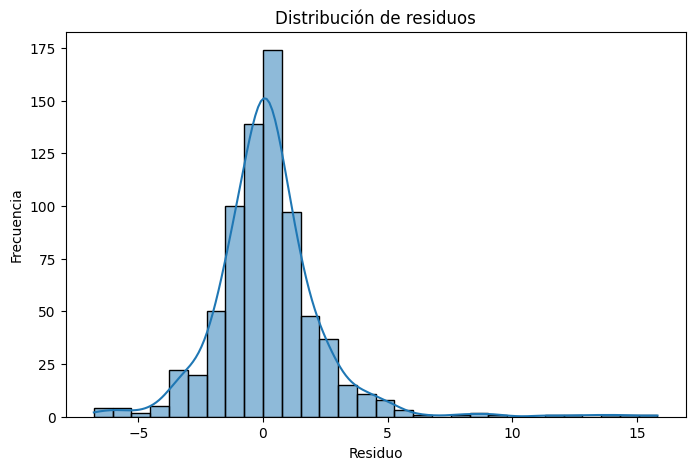

In [74]:
plt.figure(figsize=(8,5))

sns.histplot(
    residuals,
    bins=30,
    kde=True
)

plt.title("Distribución de residuos")
plt.xlabel("Residuo")
plt.ylabel("Frecuencia")

plt.show()

### Evaluación de normalidad

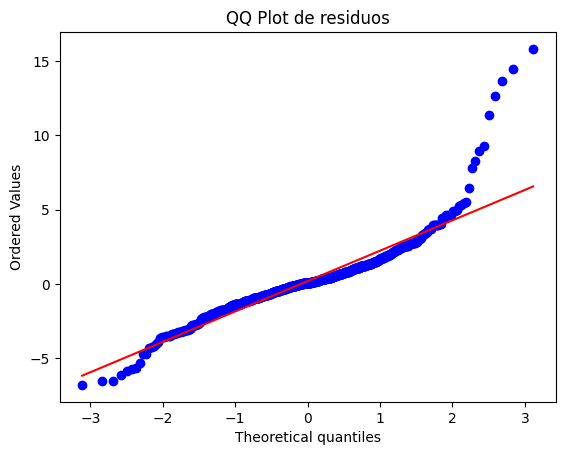

In [75]:
from scipy import stats

stats.probplot(
    residuals,
    dist="norm",
    plot=plt
)

plt.title("QQ Plot de residuos")

plt.show()

### Residuos vs valores predichos

c:\LeonellaTP\Miniconda3\envs\ml_venv\lib\site-packages\seaborn\_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
c:\LeonellaTP\Miniconda3\envs\ml_venv\lib\site-packages\seaborn\_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):


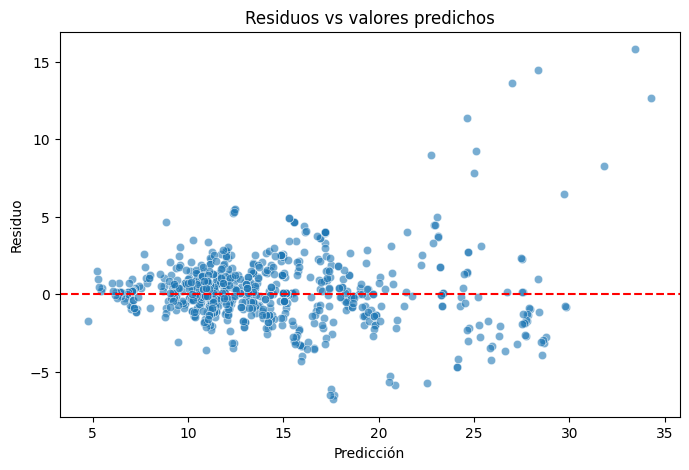

In [76]:
plt.figure(figsize=(8,5))

sns.scatterplot(
    x=svr_pred,
    y=residuals,
    alpha=0.6
)

plt.axhline(
    0,
    color="red",
    linestyle="--"
)

plt.xlabel("Predicción")
plt.ylabel("Residuo")

plt.title("Residuos vs valores predichos")

plt.show()

### Interpretación

#### Distribución de residuos

La distribución de residuos se encuentra centrada alrededor de cero, lo que indica que el modelo no presenta un sesgo sistemático importante hacia la sobreestimación o subestimación de la variable objetivo.

Sin embargo, la distribución no es completamente simétrica. Se observa una cola derecha más extensa, asociada a un reducido conjunto de observaciones con errores positivos relativamente elevados.

Este comportamiento es consistente con la presencia de activos con estructuras de costos atípicas identificadas durante el análisis exploratorio.

#### Normalidad de residuos

El gráfico Q-Q muestra una buena alineación con la distribución normal en la zona central de los datos.

No obstante, se observan desviaciones importantes en ambos extremos, especialmente en la cola superior.

Esta evidencia sugiere que los residuos no siguen una distribución normal perfecta y presentan colas más pesadas de lo esperado bajo normalidad.

El resultado es coherente con los hallazgos previos obtenidos para la variable objetivo, la cual también mostró asimetría positiva y presencia de valores extremos.

#### Heterocedasticidad

El gráfico de residuos frente a valores predichos muestra una dispersión relativamente homogénea para niveles bajos y medios de predicción.

Sin embargo, para valores predichos elevados se observa una mayor variabilidad de los residuos.

Este patrón sugiere la presencia de heterocedasticidad moderada, indicando que el error del modelo tiende a incrementarse en activos con costos de producción más altos.

Este comportamiento es razonable desde una perspectiva de negocio, dado que los activos con mayores costos suelen presentar una mayor complejidad operativa y económica.

#### Conclusión

En términos generales, los residuos se comportan de manera aceptable para un modelo base de regresión.

No obstante, la evidencia de colas pesadas, algunos valores extremos y heterocedasticidad moderada indica que existe información estructural adicional que podría capturarse mediante modelos más complejos o mediante procesos adicionales de ingeniería de características.

Estos resultados justifican la utilización de métricas complementarias como RMSE, MAPE y R² en lugar de depender exclusivamente de supuestos de normalidad.

### Autocorrelación temporal de residuos

Dado que el dataset incorpora una dimensión temporal asociada a la variable Year, se analizará la posible dependencia temporal de los residuos mediante la función de autocorrelación (ACF).

La presencia de autocorrelación significativa podría indicar que el modelo no está capturando completamente la información temporal disponible.


<Figure size 800x500 with 0 Axes>

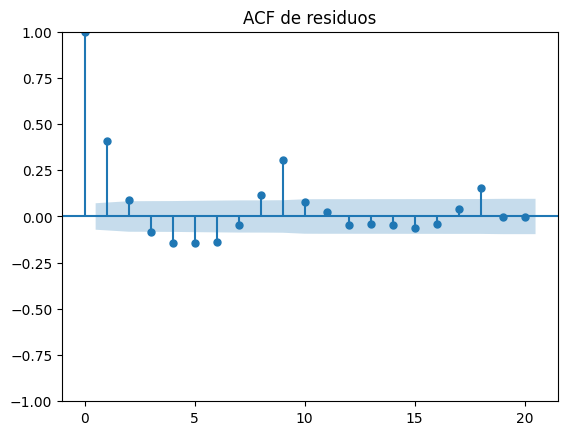

In [77]:
from statsmodels.graphics.tsaplots import plot_acf

plt.figure(figsize=(8,5))

plot_acf(
    residuals,
    lags=20
)

plt.title("ACF de residuos")

plt.show()

### Autocorrelación temporal de residuos

Se analizó la función de autocorrelación (ACF) de los residuos con el fin de identificar posibles patrones temporales no capturados por el modelo.

#### Interpretación

La función ACF muestra que la mayoría de los coeficientes de autocorrelación se encuentran dentro de las bandas de confianza, lo que indica ausencia de dependencia temporal significativa para la mayor parte de los rezagos analizados.

Sin embargo, algunos rezagos específicos presentan valores que exceden ligeramente las bandas de confianza, especialmente en los primeros rezagos y alrededor del rezago 9.

Estos resultados sugieren la existencia de una dependencia temporal residual moderada, aunque considerablemente menor que la que cabría esperar en presencia de una estructura temporal fuerte no modelada.

La evidencia obtenida indica que el modelo captura adecuadamente una proporción importante de la información temporal disponible en los datos, aunque podrían existir efectos temporales adicionales no totalmente explicados por las variables utilizadas.

#### Conclusión

No se observa una autocorrelación persistente o sistemática de los residuos.

Por consiguiente, no existe evidencia fuerte de que el modelo haya omitido patrones temporales dominantes.

Las pequeñas dependencias residuales observadas podrían estar asociadas a factores externos no incluidos en la base de datos, tales como condiciones macroeconómicas, ciclos del mercado petrolero o eventos específicos de determinadas regiones.

## 3.10 Curva de aprendizaje

Se construirá una curva de aprendizaje para analizar la evolución del desempeño del modelo a medida que aumenta el tamaño del conjunto de entrenamiento.

Esta herramienta permitirá:

- Evaluar si el tamaño de muestra disponible resulta suficiente.
- Detectar posibles problemas de sobreajuste.
- Detectar posibles problemas de subajuste.
- Analizar el potencial beneficio de incorporar observaciones adicionales.

La interpretación conjunta de la curva de aprendizaje y de las métricas de desempeño permitirá valorar la capacidad real de generalización del modelo.

In [78]:
from sklearn.model_selection import learning_curve
import numpy as np

In [79]:
train_sizes, train_scores, val_scores = learning_curve(
    svr_pipeline,
    model_df[features],
    model_df[target],
    groups=model_df["CostProductionElementName"],
    cv=gkf,
    scoring="r2",
    train_sizes=np.linspace(0.1, 1.0, 10),
    n_jobs=-1
)

In [80]:
train_mean = train_scores.mean(axis=1)
val_mean = val_scores.mean(axis=1)

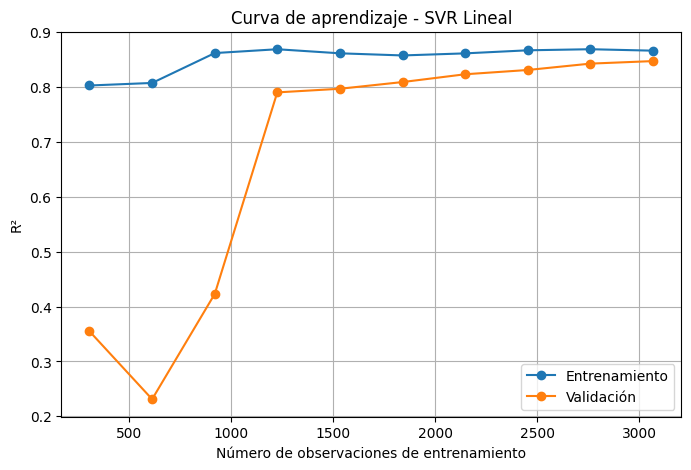

In [81]:
plt.figure(figsize=(8,5))

plt.plot(
    train_sizes,
    train_mean,
    marker="o",
    label="Entrenamiento"
)

plt.plot(
    train_sizes,
    val_mean,
    marker="o",
    label="Validación"
)

plt.xlabel("Número de observaciones de entrenamiento")
plt.ylabel("R²")

plt.title("Curva de aprendizaje - SVR Lineal")

plt.legend()

plt.grid(True)

plt.show()

### Interpretación

La curva de aprendizaje muestra la evolución del desempeño del modelo SVR lineal a medida que aumenta el tamaño del conjunto de entrenamiento.

#### Desempeño de entrenamiento

El coeficiente de determinación (R²) sobre los datos de entrenamiento permanece relativamente estable alrededor de valores entre 0.85 y 0.87.

La estabilidad observada indica que el modelo no memoriza excesivamente los datos utilizados para el entrenamiento.

#### Desempeño de validación

El desempeño sobre validación presenta una mejora progresiva conforme aumenta el número de observaciones disponibles.

Para tamaños pequeños de muestra se observa una elevada variabilidad, con valores de R² considerablemente inferiores a los obtenidos en entrenamiento.

Sin embargo, a partir de aproximadamente 1.200 observaciones las curvas comienzan a converger y alcanzan niveles de desempeño cercanos a 0.85.

#### Sobreajuste y subajuste

La distancia entre las curvas de entrenamiento y validación se reduce progresivamente a medida que aumenta el tamaño de la muestra.

Este comportamiento sugiere que el modelo no presenta problemas importantes de sobreajuste.

Tampoco se observa evidencia clara de subajuste, ya que ambas curvas alcanzan niveles elevados de desempeño y mantienen una tendencia estable.

#### Suficiencia del tamaño muestral

La convergencia observada indica que el tamaño de muestra disponible resulta adecuado para el modelo SVR lineal implementado.

Si bien podrían obtenerse mejoras marginales mediante la incorporación de observaciones adicionales, los resultados sugieren que el modelo ya captura una proporción importante de la información presente en los datos.

#### Conclusión

La curva de aprendizaje muestra una capacidad de generalización adecuada y respalda la validez del modelo base propuesto.

La convergencia entre entrenamiento y validación, junto con los resultados obtenidos en RMSE, MAPE y R², indica que el modelo logra capturar relaciones relevantes entre las variables predictoras y el BrentEquivalentProductionCost sin evidencia fuerte de sobreajuste.

## 3.11 Comparación de modelos

Se compararán explícitamente:

- DummyRegressor.
- SVR Lineal (Configuración principal).

Opcionalmente se incorporará una configuración ampliada para evaluar el efecto de variables económicas potencialmente redundantes identificadas durante la auditoría de fuga de información.

La selección final se realizará considerando desempeño predictivo, interpretabilidad y robustez metodológica.

In [82]:
results = {
    "Modelo": ["Dummy Regressor", "SVR Lineal"], 
    "RMSE": [dummy_rmse, svr_rmse],
    "MAPE": [dummy_mape, svr_mape],
    "R²": [dummy_r2, svr_r2]
} 


In [83]:
# resultado de la evaluación de los modelos
results_df = pd.DataFrame(results)
results_df

,Modelo,RMSE,MAPE,R²
0,Dummy Regressor,5.821851,0.318703,-0.003729
1,SVR Lineal,2.194960,0.094461,0.857325


### Consideración sobre posible fuga de información

El modelo obtuvo un R² de 0.857, valor que se encuentra dentro del rango señalado por la guía como potencialmente susceptible a fuga de información.

Como medida de control, durante la auditoría de Data Leakage se evaluaron las variables altamente correlacionadas con la variable objetivo, así como los niveles de multicolinealidad identificados mediante VIF y PCA.

Adicionalmente, la partición por grupos utilizando CostProductionElementName evitó que observaciones pertenecientes al mismo activo aparecieran simultáneamente en entrenamiento y prueba.

No obstante, futuros trabajos podrían profundizar en este análisis comparando configuraciones alternativas de variables predictoras con el fin de evaluar la sensibilidad del desempeño observado frente a posibles variables proxy de la variable objetivo.

### Interpretación final de resultados

La comparación entre la línea base trivial y el modelo SVR lineal evidencia una mejora sustancial en todas las métricas evaluadas.

| Modelo | RMSE | MAPE | R² |
|----------|----------:|----------:|----------:|
| Dummy Regressor | 5.82 | 31.87% | -0.004 |
| SVR Lineal | 2.19 | 9.45% | 0.857 |

El DummyRegressor presenta un desempeño muy limitado, obteniendo un R² prácticamente nulo (-0.004). Este resultado era esperado, ya que el modelo genera predicciones utilizando únicamente el valor promedio de la variable objetivo sin considerar información asociada a los activos.

Por el contrario, el modelo SVR lineal logra una reducción importante del error de predicción.

El RMSE disminuye de 5.82 a 2.19 USD/Bbl, mientras que el error porcentual promedio (MAPE) se reduce de aproximadamente 31.9% a 9.4%.

Adicionalmente, el modelo alcanza un coeficiente de determinación de 0.857, indicando que aproximadamente el 85.7% de la variabilidad observada en BrentEquivalentProductionCost puede explicarse mediante las variables incluidas en el modelo.

Los intervalos de confianza obtenidos mediante bootstrap mostraron resultados relativamente estables:

- RMSE: [1.96, 2.48]
- MAPE: [8.84%, 10.07%]
- R²: [0.837, 0.878]

Estos resultados sugieren que el desempeño del modelo es consistente frente a variaciones en la muestra analizada.

El análisis de residuos mostró una distribución centrada alrededor de cero, ausencia de sesgos sistemáticos importantes y una autocorrelación temporal limitada.

Asimismo, la curva de aprendizaje evidenció una adecuada capacidad de generalización y ausencia de problemas significativos de sobreajuste.

En conjunto, los resultados permiten concluir que el modelo SVR lineal constituye una aproximación inicial sólida para la predicción del BrentEquivalentProductionCost y supera ampliamente el desempeño de la línea base trivial.

## Conclusiones del análisis exploratorio

Principales hallazgos:

- La variable objetivo presenta asimetría positiva y colas pesadas.
- Production exhibe una fuerte dispersión y valores extremos.
- ReserveTypeName mostró el mayor tamaño de efecto sobre la variable objetivo.
- Se identificó multicolinealidad importante entre variables de costos.
- El modelo SVR lineal alcanzó un R² de 0.857.
- El error porcentual promedio fue inferior al 10%.